# The ETROC2 charge-injection archive: what exists, where it lives, and what was monitored while it was taken

> **Charge convention, corrected 2026-10-18.** The ETROC2 Reference Manual (rev 0.60, §3.1.4 and
> Table 14 row 6, QSel[4:0]; bit position in Table 15) gives the injected charge as
> **(QSel + 1) fC**, 1 to 32 fC, accurate to about ±15 %.
> Every 2024 campaign in this folder was taken with the original i2c_gui scripts, which name each
> point `QInj_<N>` with N the QSel register value, so the physical charge of a `QInj_N` point is
> **N + 1 fC**. Until 2026-10-18 these notebooks plotted N as the charge. The loaders in
> `qinj_common.py` now add the offset (`QSEL_LABEL_OFFSET_FC = 1`); the staged tables under `data/`
> are unchanged and keep the recorded labels. Fit windows and charge thresholds moved by +1 with
> the axis, so they select the same data points as before: preamp-gain (charge-to-threshold)
> slopes and ENC are unchanged, fit intercepts move by −(slope × 1 fC), the minimum charge reaching
> BL+20 (`Q_min`) moves by +1 fC, and the TOT-against-ln Q law, which is not shift-invariant, was
> refitted. Comparisons with earlier published numbers convert back to the label axis at the
> point of comparison.

This notebook is the **inventory** for the rest of the folder. It does not fit anything. It
answers four questions, from staged tables and from auxiliary logs that no other notebook here
plots:

1. **What counts as a charge-injection data set** — and, just as importantly, what looks like one
   and is not.
2. **What exists**, across every storage location that has been scanned — six of them, counted
   in cell 5.0: 31 data sets, positive
   and negative, with the revision, the device, the charges, the threshold range and the size of
   each.
3. **What was monitored while each campaign ran** — supply rails, baselines, on-chip temperature,
   sensor bias, the voltage reference, the chamber — and, campaign by campaign, what could have
   been logged and was not.
4. **Which of it is analysed here**, and what is still untouched.

Every number in the prose comes from a cell above it or from a staged table. Quantities are
labelled **RAW** (a column, or a direct byte, of a source file) or **DERIVED** (computed here).
Where a campaign did not record something the text says `not recorded`, and where a scan did not
look, it says `unknown` — the two are different and are never merged.

---

## 1. What a charge-injection data set is

Every ETROC2 pixel carries a small **injection capacitor at the preamplifier input**. Writing the
5-bit `QSel` field of the pixel configuration selects a charge of **(QSel + 1) fC**, 1 to 32 fC
(manual §3.1.4), and each Level-1 accept then delivers that charge step to the front end, with
no sensor involved.
It is the only measurement in the ETROC programme where **the input charge is a number we set**
rather than whatever a sensor happened to produce.

A **charge-injection data set** — a *money plot* — is the two-dimensional scan that measurement
implies:

> for each injected **charge**, step the per-pixel threshold **DAC** through the pixel's
> response and record **TOA, TOT and CAL for every hit at every point.**

Both axes have to be swept. Charge alone gives no threshold-edge width and therefore no noise
measurement; threshold alone gives no preamp gain, because preamp gain *is* the slope of the discriminator
turn-off against charge. The per-point TOA standard deviation against threshold, one curve per
charge, is the figure the whole exercise is named after.

In the archive a data set of that kind is recognisable from directory names alone: one directory
per point, named

```
<chip>_VRef_SCurve_TDC_Pixel_C<col>_R<row>_QInj_<QSel value N>_Threshold_<dac>
```

with sibling `..._BinarySearch_TurnOff_...` directories (the discriminator's own 50 %-efficiency
search, which carries a real Level-1-accept denominator) and `..._NoiseOnly_..._quietCB`
directories (the same search with no injection). For the 2024 campaigns N is the QSel register
value and the injected charge is N + 1 fC.

**The `_VRef_` token in those names is a trap.** It labels the scan setup — the threshold DAC is
the pixel's reference voltage — and it is **not** a record of any VRef *setting*. No data set in
this census records a VRef value in a directory name.

### A single-point charge-injection run is not a money plot

The commonest near-miss, and by number of runs the most abundant kind of charge-injection data in
existence, is the **single-point run**: the injector is enabled at one charge, the threshold is
parked at one offset above the autocalibrated baseline, and one acquisition is taken. It is the
right tool for its job — checking that a module reads out before and after a test beam — and it
is useless for calibration, because with one charge there is no preamp gain and with one threshold there
is no edge.

Row 17 below is 326 such runs, all at charge label **30** with the threshold at **baseline + 20 DAC**. Row 4
is one run at label 30 recorded with a waveform sampler and no TDC data at all. Row 8 is 524
probe-station runs whose charge is not recorded anywhere. None of the three can produce a money
plot, and the census says so in the `has_threshold_scan` column rather than in a footnote. (The
label 30 of rows 4 and 17 is the recorded `QInj30` label of 2025–2026 software; whether those tools
write QSel or the charge is not established here, so it is left as recorded. Row 11, a 2025
configuration file rather than data, records the register outright as `30 (qsel 0x1e)`: QSel 30,
which is 31 fC by the manual. The census `charges_fC` column keeps every row's recorded label.)

## 2. Where ETROC data has lived

The programme has never had one archive, and the census is shaped by that:

* **LPC EOS**, `root://cmseos.fnal.gov//store/group/lpcmtdstudies` — the nearest thing to a
  central store. The two CERN January-2024 campaigns, the wafer-probe trees, the beam trees and
  the seven `SEU_*` trees are here.
* **`fermilab-etroc3`**, the FNAL bench PC — its local `/home/daq` and, mounted on it, the
  **removable exFAT disk labelled X9**. The whole ET2.03 charge-injection programme of 2024 is on
  that disk, and the disk is the master copy: most of it has no copy anywhere else.
* **`fermilab-etroc5`**, the newer bench PC — the 2026 module-qualification runs and, with them,
  the best-instrumented monitoring in the census. None of it is backed up to EOS at either
  laboratory.
* **lxplus**, CERN EOS and AFS — code, notebooks, rendered figures and beam products. No
  charge-injection data at all (row 24, a clean negative verified to depth 6 across twelve
  campaign trees).
* **Laptops and disks that have moved on** — rows 15 and 16. Two directories that acquisition
  scripts wrote to no longer exist on the machine that wrote them. One of the two turned out to
  be archived on EOS after all (rows 26 and 30); the other is probably a third copy of row 3.

## 3. How this census was made, and what it cannot see

Rows 1-16 come from a read-only scan of LPC EOS and `fermilab-etroc3` completed 2026-09-02; rows
17-31 from a second read-only scan of lxplus, `fermilab-etroc5` and the LPC EOS `SEU_*` trees
completed 2026-09-04. Both used `ls`, bounded `find`, `du`, `head`, `wc`, `unzip -l` for listing
only, and read-only SQLite queries. Nothing was written, moved or deleted anywhere, and the
~120 000 scan-directory names were parsed into per-day summaries rather than listed.

Four limits travel with the result and none of them can be argued away:

* **It is a name-based search.** Device, revision, charge, power mode and temperature were
  recorded only where a token in a directory name, a metadata key or a configuration file states
  them. Where nothing states them the cell reads `unknown`, even where a guess would have been
  easy.
* **An archive is opaque to a name-based search.** The single largest charge-injection tree found
  anywhere (row 25, 59 048 point directories) was inside a `.tar.gz` that a `find` reports as one
  file. It was found by listing the archive, not by searching names. Row 25's own caveat is the
  general one: **any remaining tarball is an unsearched location**, and at least one large laptop
  backup archive on LPC EOS has never been opened.
* **RFSel is recorded nowhere.** Not in one of the ~120 000 scan-directory names, not in any
  configuration file, not in any acquisition script, on any of the six storage locations the
  census carries (the count is printed in cell 5.0). RFSel sets the
  preamplifier feedback resistance and therefore preamp gain and TOT directly, so this is the single
  largest unquantified systematic in every notebook in this folder. `power_mode` and `gain_mode`
  *are* recorded, but only from June 2026 onward and only on `fermilab-etroc5`.
* **Two locations were not readable and are therefore not represented.** A colleague's CERN EOS
  area, and four non-`daq` home directories on `fermilab-etroc5`. Zero hits from a path that
  returns "permission denied" is not a negative result; it is no result, and nothing was done to
  work around either.
* **Modification times are not acquisition times on a copied disk.** Whole trees carry the
  timestamp of the copy that made them: rows 1 and 3 show 2024-01-27 throughout, row 8 shows a
  single bulk-copy minute, and the backup disk of section 3.1 did not preserve timestamps at all,
  so its mtimes carry no information whatever. Every date in the census comes from a directory
  name, a metadata field or a timestamp column *inside* a file — never from an mtime.

### 3.1 What the search actually walked, and one place it paid off

The method is a search over **folder names**, run over each storage location in turn, and its
blind spots are the direct consequence of that: a folder whose name says nothing is invisible to
it, and so is everything inside an archive. Two of the most useful things in this notebook were
found by walking names one more level rather than by any cleverness — the archive of row 25, and
the per-campaign monitoring folders of the `etroclaptop3` backup on the **X9 removable disk**
(`/run/media/daq/X9/etroclaptop3_backup_20251127/ETROC-History/`).

That backup holds nineteen per-campaign history folders. One of them, `CERN_Aug_2024_CC_CTS`, is
analysed in section 7.6 because it is the only ET2.03 voltage-reference record in existence. The
other eighteen belong to campaigns that are outside this folder's scope — beam tests, suitcase
tests, SEU runs — and they are **listed here and not analysed**, because a reader asking "was
anything monitored during campaign X" should be able to answer it from this notebook without
repeating the search.

In [1]:
import sys
from pathlib import Path

import matplotlib.pyplot as plt
import matplotlib.patches as mpatches
import numpy as np
import pandas as pd

sys.path.insert(0, str(Path.cwd()))
import qinj_common as Q
from qinj_style import INK, apply_style

apply_style(0.55)
pd.set_option("display.width", 200, "display.max_columns", 60, "display.max_colwidth", 64)

CAMP = Q.CENSUS_CAMPAIGN


def header(fig, name, tag=None, scale=0.62, y=1.012, pad=6):
    return Q.fig_header(fig, name, tag=tag, scale=scale, campaign=CAMP, y=y, pad=pad)


print("staged census directory:", Q.CENSUS_DIR)

staged census directory: /Users/murtazas/cms/ETROC-Analysis-wt-qinj/qinj_studies/data/census


## 4. Provenance of everything this notebook reads

Seven files, all under `data/census/`. Two are inventories — a transcription of what the two
scans found — and five are auxiliary data extracted or copied for this notebook. Full detail,
including the extraction recipe and what was deliberately left out, is in
`data/census/PROVENANCE.md`.

| file | RAW / DERIVED | what it is |
|---|---|---|
| `qinj_census.csv` | DERIVED | one row per data set, 31 × 24. The inventory. |
| `qinj_aux_matrix.csv` | DERIVED | one row per campaign, one column per kind of monitoring. |
| `aux_tid_lv_timeseries.csv.gz` | RAW, downsampled | the analog and digital supply rails of the CERN January-2024 TID campaign, one sample per rail per minute of 231 120. |
| `aux_tid_lv_actions.csv` | RAW | the logger's own Start/Stop rows, which date the power-down stretches. |
| `aux_tid_baseline_history.csv` | RAW | that campaign's entire baseline log: two full-array autocalibration repeats, 23 minutes. |
| `aux_et2p03_chipconfig.csv` | RAW, decoded | the three ET2.03 August-2024 register read-backs. |
| `aux_et2p03_blnw.csv` | RAW | the ET2.03 `BARE9` baseline and noise-width maps, all 256 pixels. |
| `aux_ccts_vol.csv.gz` | RAW, downsampled | the ET2.03 **internal VRef** and **on-chip VTemp** of the August-2024 climate-chamber set, 1 sample/instrument/minute of 336 166. |
| `aux_ccts_chamber.csv.gz` | RAW, downsampled | that campaign's chamber air temperature and humidity, 1/minute of 85 779. |
| `aux_ccts_lv.csv.gz`, `aux_ccts_lv_actions.csv` | RAW | its supply rails (1/instrument/rail/minute of 350 489) and the logger's own action rows. |
| `aux_ccts_blnw.csv.gz` | RAW | its 140 full 16 × 16 autocalibration maps, 35 840 rows, with the condition text parsed into four columns. |
| `aux_tid_et2p03_timeline.csv` | RAW, transcribed | the ET2.03 August-2024 irradiation start/stop markers, read off the analysis notebook of section 7.7. |
| `census_x9_history_folders.csv` | RAW | one `ls` per per-campaign history folder of the backup disk of section 3.1. |

In [2]:
# 4.1  What is staged, with sizes and checksums recomputed here.
prov = pd.DataFrame([Q.file_row(p) for p in sorted(Q.CENSUS_DIR.iterdir())
                     if p.is_file() and p.name != "PROVENANCE.md"])
prov["kB"] = (prov.bytes / 1024).round(1)
print(prov[["file", "bytes", "kB", "md5"]].to_string(index=False))
print()
print("The two ET2.03 files are byte-for-byte copies of the ET2.03 reduction's own tables;")
print("their md5 values there are 5aef7758fd020bddf206430880301a20 (chipconfig) and")
print("96da68fed9fef08cf920002f4bfa5023 (blnw). Recomputed above:")
for f, want in [("aux_et2p03_chipconfig.csv", "5aef7758fd020bddf206430880301a20"),
                ("aux_et2p03_blnw.csv", "96da68fed9fef08cf920002f4bfa5023")]:
    got = prov.loc[prov.file == f, "md5"].iloc[0]
    print(f"  {f:<30s} {got}  {'MATCH' if got == want else 'DIFFERS'}")

                         file  bytes    kB                              md5
         aux_ccts_blnw.csv.gz 390706 381.5 421f81df91dcad68ac075e627fd510b1
      aux_ccts_chamber.csv.gz  59554  58.2 a4e0ee163be1683124e9f7cf1a30c1ff
           aux_ccts_lv.csv.gz 224893 219.6 b8e8731283c5dac6e56f219690935964
      aux_ccts_lv_actions.csv  21962  21.4 90a1ac41ea65c22cd22fb7adbce3bb61
          aux_ccts_vol.csv.gz 175344 171.2 2e1b161c93115e84448e89672496a37c
          aux_et2p03_blnw.csv  14833  14.5 96da68fed9fef08cf920002f4bfa5023
    aux_et2p03_chipconfig.csv   3164   3.1 5aef7758fd020bddf206430880301a20
 aux_tid_baseline_history.csv  84803  82.8 60f056bf91b1444efce65208a7a994ef
  aux_tid_et2p03_timeline.csv    738   0.7 bfa86d85a080a291e4e6e559fdc938db
       aux_tid_lv_actions.csv    522   0.5 175bc9762152207a1afe27adac3115fe
 aux_tid_lv_timeseries.csv.gz 153597 150.0 6672b01ca9962224c36ba6873b8e0150
census_x9_history_folders.csv   1436   1.4 f53ffc3f2aa1ebe12f204c5d1a901f3e
          qi

## 5. The census table

One row per data set. **Negative rows are rows, not footnotes** — a place where charge-injection
data would be expected and there is none is as load-bearing as a place where there is some, and
eleven of the 31 rows are of that kind.

In [3]:
CEN = Q.load_census()
print("census: %d rows x %d columns" % CEN.shape)
N_LOC = int(CEN.location.nunique())
N_HOST = int(CEN.host.nunique())
print("distinct storage locations: %d  %s" % (N_LOC, sorted(CEN.location.unique())))
print("distinct hosts            : %d  %s" % (N_HOST, sorted(CEN.host.dropna().unique())))
print()
print(CEN[["id", "location", "campaign", "date_start", "date_end", "revision", "device",
           "purpose", "has_threshold_scan"]].to_string(index=False))

census: 33 rows x 27 columns
distinct storage locations: 7  ['LPC EOS', 'X9 removable disk', 'X9 removable disk; LPC EOS', 'local disk', 'lxplus EOS', 'lxplus EOS and AFS', 'removable disks']
distinct hosts            : 5  ['cmseos.fnal.gov', 'eosuser.cern.ch', 'fermilab-etroc3', 'fermilab-etroc5', 'lxplus.cern.ch']

id                   location                                 campaign date_start   date_end                                                          revision             device                       purpose has_threshold_scan
 1                    LPC EOS                        CERN Jan-2024 TID 2024-01-04 2024-01-19                                                            ET2.01               bare                           TID                yes
 2                    LPC EOS                        CERN Jan-2024 TID 2024-01-04 2024-01-19                                                            ET2.01               bare                           TID      yes (reduced)


In [4]:
# 5.1  The charges, thresholds and pixels of every row that carries a real threshold scan.
#      `charges_fC` is the census text as recorded from directory names and documents: for the
#      2024 campaigns these are QSel labels (physical charge = label + 1 fC); the later rows mix
#      software generations and are left as recorded.
scan = CEN[CEN.has_threshold_scan.str.startswith("yes")]
print("%d of %d rows carry a charge x threshold scan.\n" % (len(scan), len(CEN)))
print(scan[["id", "campaign", "revision", "device", "charges_fC", "dac_range", "pixels",
            "analysed_in_notebook"]].to_string(index=False))

7 of 33 rows carry a charge x threshold scan.

id                            campaign                 revision device                                       charges_fC                                  dac_range                               pixels analysed_in_notebook
 1                   CERN Jan-2024 TID                   ET2.01   bare                                   5;6;8;15;22;27                                    435-922 17: C{2,7,8,14} x R{0,1,3,12} + C5R5                  1.0
 2                   CERN Jan-2024 TID                   ET2.01   bare                                   5;6;8;15;22;27                       435-915 (481 values)          12: R{0,1,3,12} x C{2,8,14}                  1.0
 3       CERN Jan-2024 climate chamber                   ET2.01 hybrid                                   5;6;8;15;22;27                                    400-743     18: C{2,8,14} x R{0,2,3,8,12,14}                  2.0
 5                 FNAL Jul-2024 bench ET2.03 (ET2.01 on 07-22)   bar

In [5]:
# 5.2  Size and format of every row where a size was measured.
sz = CEN[CEN.size_GB_num.notna()].sort_values("size_GB_num", ascending=False)
print(sz[["id", "location", "campaign", "size_GB_num", "format", "size_note"]]
      .rename(columns={"size_GB_num": "GB"}).to_string(index=False))
print("\ntotal of the measured rows: %.1f GB over %d data sets" % (sz.size_GB_num.sum(), len(sz)))
print("rows with no measured size: %d (see size_note)" % int(CEN.size_GB_num.isna().sum()))

id                   location                                 campaign           GB                                                                              format                                                          size_note
 3                    LPC EOS            CERN Jan-2024 climate chamber 7.600000e+01                                  *.nem; *.bin; FPGA_Data.dat; BL/NW pickles; sqlite                                                       39,680 files
 6          X9 removable disk                  CERN Aug-2024 X-ray TID 3.990000e+01                                    TDC_Data_*.bin; FPGA_Data.dat; ChipConfig/*.pckl 25.1 GB copied to LPC scratch on 2026-09-04; 14.7 GB still X9-only
 5 X9 removable disk; LPC EOS                      FNAL Jul-2024 bench 3.880000e+01                                                            .nem then TDC_Data_*.bin                                              part of an 80 GB tree
12                    LPC EOS                    wafer probe

### 5.3 Revision × device × purpose

The matrix below is the census's single most useful summary, because the empty cells are what
decide what can be measured. Cell contents are row ids; an empty cell means **no data set of that
kind exists on any location this census has scanned.**

In [6]:
REV = ["ET2 (first)", "ET2.01", "ET2.02", "ET2.03", "unknown / mixed"]
PUR = ["TID", "climate", "bench", "single-point", "probe", "SEU", "other"]


def rev_bin(s):
    s = s.strip()
    if s.startswith("ET2 "):
        return "ET2 (first)"
    for r in ("ET2.01", "ET2.02", "ET2.03"):
        if s.startswith(r):
            return r
    return "unknown / mixed"


def pur_bin(s):
    s = s.strip()
    for p in ("TID", "climate", "bench", "single-point", "probe", "SEU"):
        if s.startswith(p):
            return p
    return "other"


def dev_bin(s):
    s = s.strip()
    if s.startswith("bare"):
        return "bare"
    if s.startswith("hybrid"):
        return "hybrid"
    return "both / unknown"


M = CEN.copy()
M["rev_bin"] = M.revision.map(rev_bin)
M["pur_bin"] = M.purpose.map(pur_bin)
M["dev_bin"] = M.device.map(dev_bin)
M["scan_bin"] = M.has_threshold_scan.str.startswith("yes")

for dev in ["bare", "hybrid", "both / unknown"]:
    print("=== %s" % dev)
    g = M[M.dev_bin == dev]
    tab = pd.DataFrame("", index=REV, columns=PUR)
    for (r, p), gg in g.groupby(["rev_bin", "pur_bin"]):
        tab.loc[r, p] = " ".join(gg.id)
    print(tab.to_string())
    print()

=== bare
                 TID climate bench single-point probe       SEU other
ET2 (first)                                                          
ET2.01           1 2                                   16 25 26      
ET2.02                                                               
ET2.03           6 7   32 33     5                        27 29      
unknown / mixed                                     8              12

=== hybrid
                TID climate bench single-point probe SEU     other
ET2 (first)                                                     22
ET2.01                    3                  4            11 15 23
ET2.02                                                       13 21
ET2.03                                                            
unknown / mixed                                                   

=== both / unknown
                TID climate bench single-point probe       SEU           other
ET2 (first)                                               

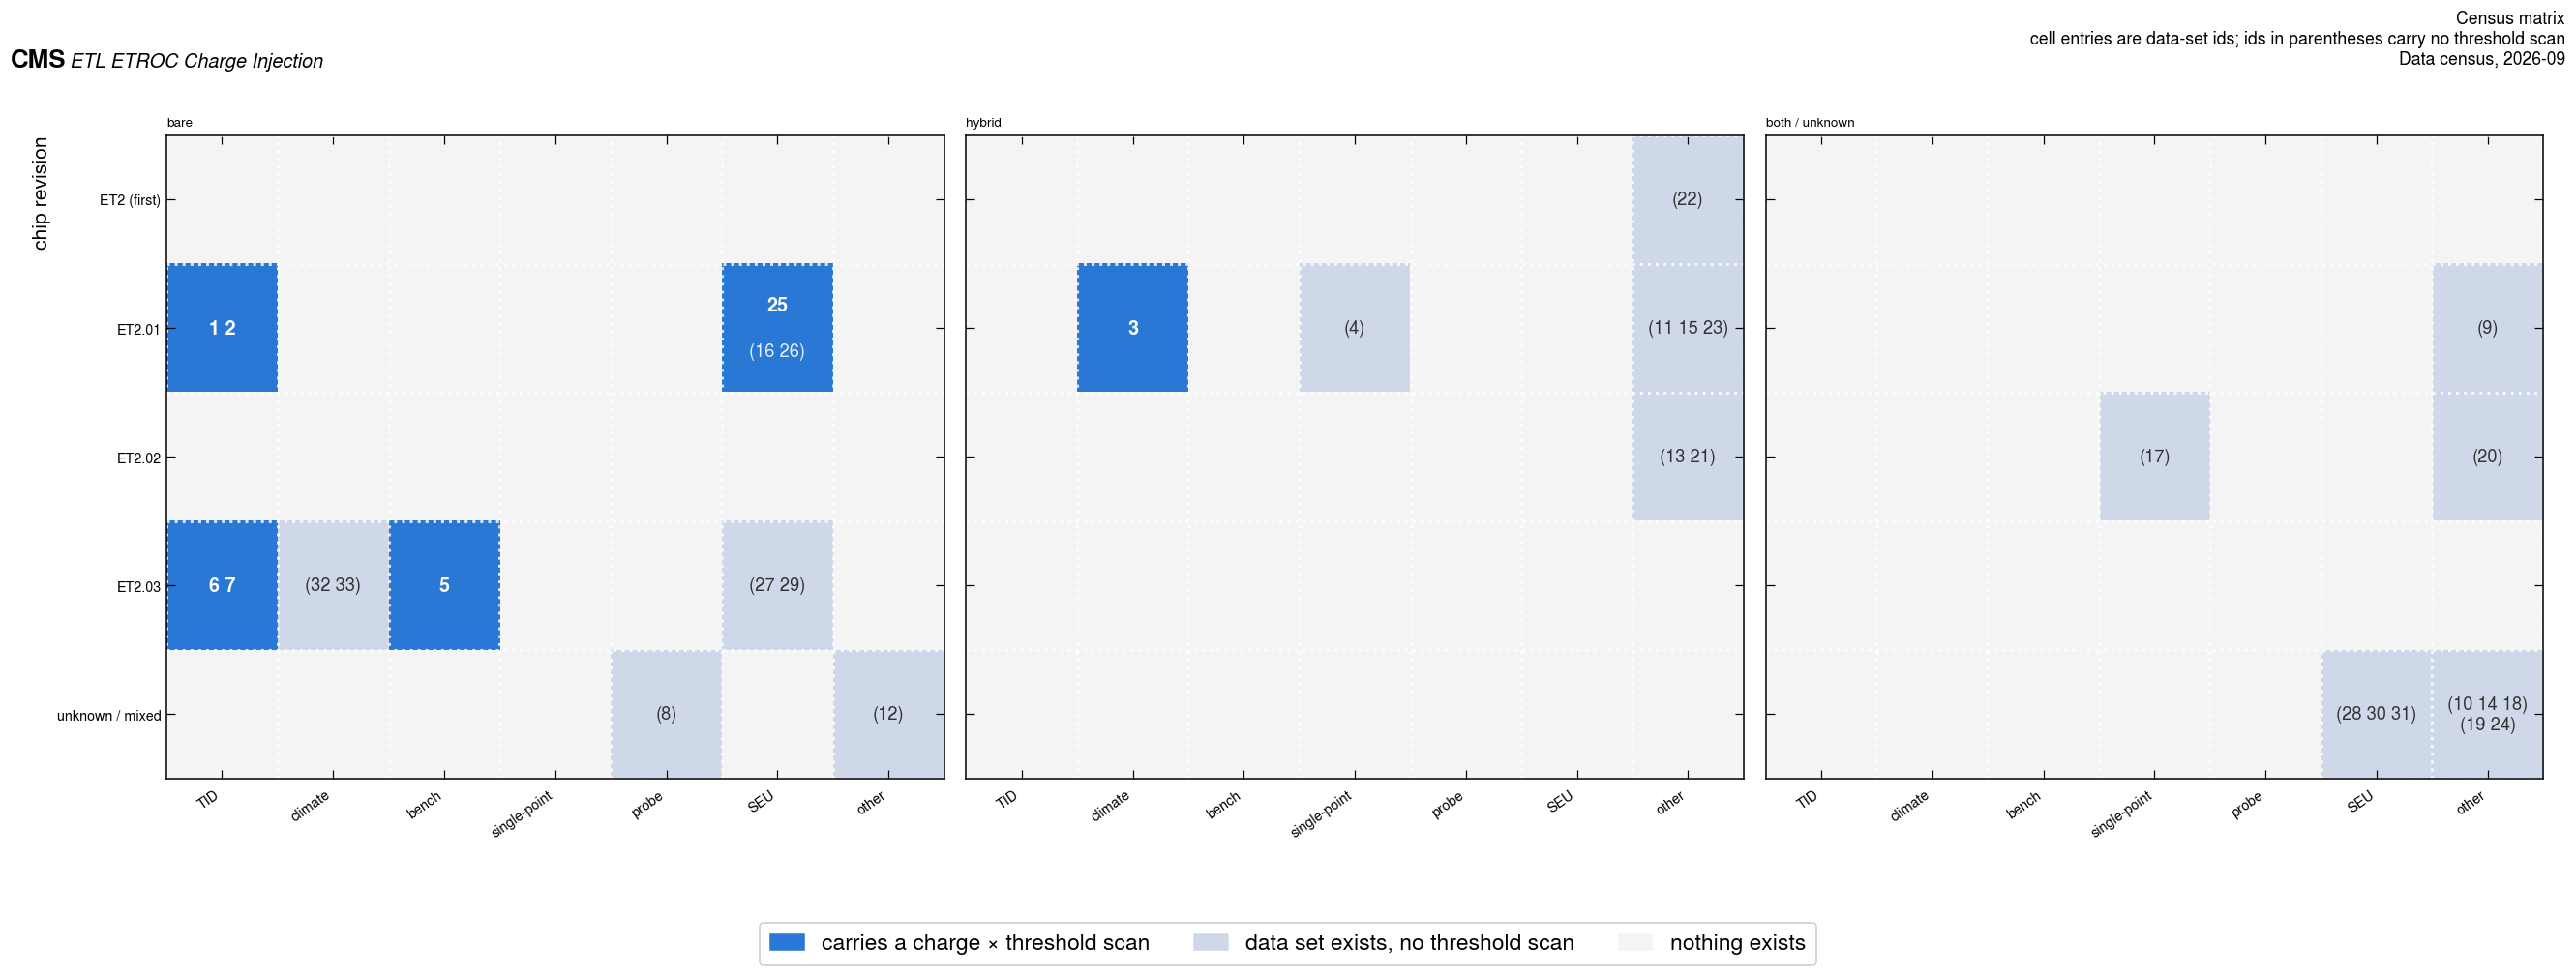

In [7]:
# 5.4  FIGURE 1 — the same matrix as a grid, with the rows that carry a threshold scan
#      distinguished from the rows that do not. Bold ids carry a scan.
DEVS = ["bare", "hybrid", "both / unknown"]
fig, axes = plt.subplots(1, 3, figsize=(24, 7.2), sharey=True)
for ax, dev in zip(axes, DEVS):
    g = M[M.dev_bin == dev]
    grid = np.zeros((len(REV), len(PUR)))
    for i, r in enumerate(REV):
        for j, p in enumerate(PUR):
            sel = g[(g.rev_bin == r) & (g.pur_bin == p)]
            if len(sel) == 0:
                continue
            grid[i, j] = 2 if sel.scan_bin.any() else 1
            def wrap(ids, per=3):
                return "\n".join(" ".join(ids[k:k + per]) for k in range(0, len(ids), per))

            with_scan = list(sel[sel.scan_bin].id)
            without = list(sel[~sel.scan_bin].id)
            if with_scan:
                ax.text(j, i - (0.18 if without else 0.0), wrap(with_scan), ha="center",
                        va="center", fontsize=13, fontweight="bold", color="#ffffff")
            if without:
                ax.text(j, i + (0.18 if with_scan else 0.0),
                        "(%s)" % wrap(without).replace("\n", ")\n("), ha="center",
                        va="center", fontsize=12,
                        color="#e8eefb" if with_scan else "#333333")
    ax.imshow(grid, cmap=plt.matplotlib.colors.ListedColormap(
        ["#f4f4f4", "#cfd8e8", Q.C_BLUE]), vmin=0, vmax=2, aspect="auto")
    ax.set_xticks(range(len(PUR)))
    ax.set_xticklabels(PUR, rotation=35, ha="right")
    ax.set_yticks(range(len(REV)))
    ax.set_yticklabels(REV)
    ax.set_title(dev, loc="left")
    ax.set_xticks(np.arange(-0.5, len(PUR)), minor=True)
    ax.set_yticks(np.arange(-0.5, len(REV)), minor=True)
    ax.grid(which="minor", color="#ffffff", linewidth=2)
    ax.grid(which="major", visible=False)
    ax.tick_params(which="minor", length=0)
axes[0].set_ylabel("chip revision")
fig.legend(handles=[mpatches.Patch(color=Q.C_BLUE, label="carries a charge × threshold scan"),
                    mpatches.Patch(color="#cfd8e8", label="data set exists, no threshold scan"),
                    mpatches.Patch(color="#f4f4f4", label="nothing exists")],
           loc="lower center", ncol=3, bbox_to_anchor=(0.5, -0.15), fontsize=15)
fig.tight_layout()
header(fig, "Census matrix",
       tag="cell entries are data-set ids; ids in parentheses carry no threshold scan",
       scale=0.72, y=1.03)
Q.save_fig(fig, "census_fig1_matrix")
plt.show()

**Three things fall straight out of the matrix, and they set the scope of every other notebook
in this folder.**

1. **Exactly one hybrid charge × threshold scan exists anywhere** — row 3, the CERN January-2024
   climate chamber, which notebook 02 analyses. Everything else on a sensor-loaded front end is
   either a single charge or a rendered figure.
2. **Every ET2.03 data set is bare and every hybrid data set is ET2.01 or older.** The two axes
   never cross: there is no ET2.03 hybrid charge-injection data.
3. **There is ET2.02 charge-injection data, and none of it is a money plot** (row 17, 326 runs,
   one charge, one threshold). Since ET2.02 is the revision in the beam telescopes, the absolute
   DAC-to-millivolt scale used in this folder cannot be validated on the revision it will be
   applied to. That is why every figure here plots **offset above baseline** rather than
   absolute DAC.

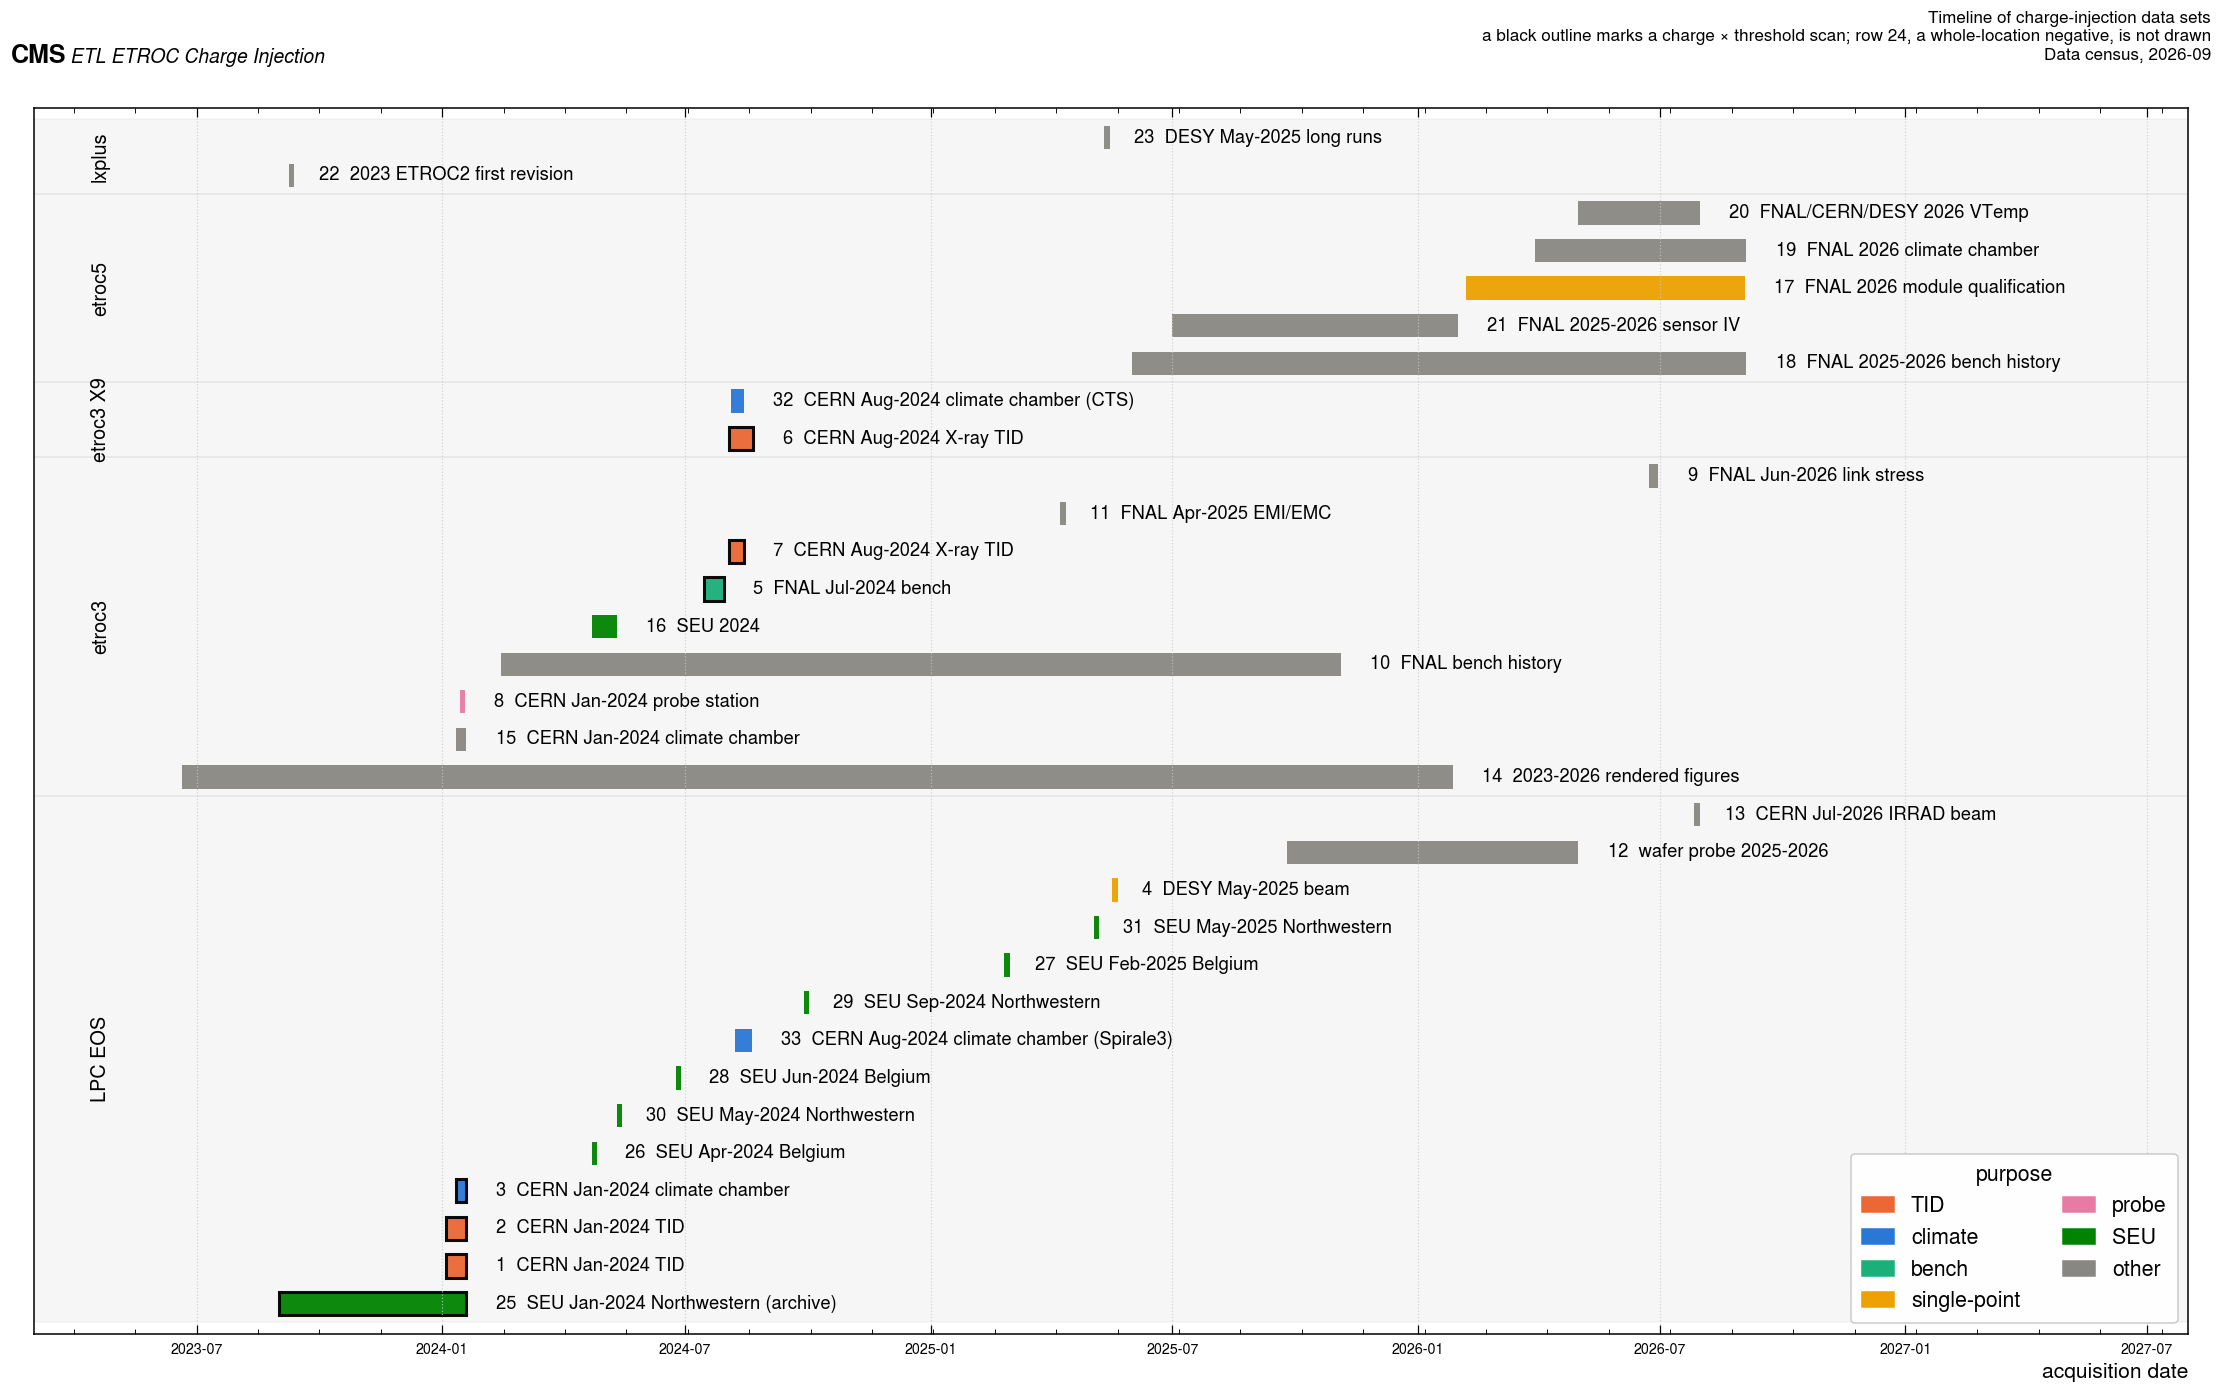

In [8]:
# 5.5  FIGURE 2 — the timeline. One bar per data set, coloured by purpose, grouped by location.
PCOL = {"TID": Q.C_ORANGE, "climate": Q.C_BLUE, "bench": Q.C_AQUA, "single-point": Q.C_YELLOW,
        "probe": Q.C_MAG, "SEU": Q.C_GREEN, "other": Q.GREY}
T = CEN.copy()
T["pur_bin"] = T.purpose.map(pur_bin)
T["loc_bin"] = T.location.replace({"X9 removable disk": "fermilab-etroc3 (X9)",
                                   "local disk": "FNAL bench PCs",
                                   "removable disks": "FNAL bench PCs",
                                   "lxplus EOS and AFS": "lxplus"})
T.loc[T.host == "fermilab-etroc5", "loc_bin"] = "fermilab-etroc5"
T.loc[T.host == "fermilab-etroc3", "loc_bin"] = "fermilab-etroc3"
T.loc[T.location == "X9 removable disk", "loc_bin"] = "fermilab-etroc3 (X9)"
T.loc[T.location == "lxplus EOS", "loc_bin"] = "lxplus"
ORDER = ["LPC EOS", "fermilab-etroc3", "fermilab-etroc3 (X9)", "fermilab-etroc5", "lxplus"]
T["loc_bin"] = pd.Categorical(T.loc_bin, categories=ORDER, ordered=True)
# Row 24 is a whole-location negative ("no charge-injection data on lxplus at all"), not a data
# set with an acquisition window, so it is not drawn; it is stated in the caption instead.
T = T[T.id != "24"].sort_values(["loc_bin", "date_start_dt"]).reset_index(drop=True)

fig, ax = plt.subplots(figsize=(20, 12))
ymap, y = {}, 0
for i, r in T.iterrows():
    ymap[r.id] = y
    span = max((r.date_end_dt - r.date_start_dt).days, 4)
    ax.barh(y, span, left=r.date_start_dt, height=0.62, color=PCOL[r.pur_bin],
            edgecolor=INK if r.has_threshold_scan.startswith("yes") else "none",
            linewidth=2.0, alpha=0.95)
    ax.text(r.date_end_dt + pd.Timedelta(days=22), y,
            "%s  %s" % (r.id, r.campaign), va="center", fontsize=12, color=INK)
    y += 1
for L in ORDER:
    ys = [ymap[i] for i in T[T.loc_bin == L].id]
    if not ys:
        continue
    ax.axhspan(min(ys) - 0.5, max(ys) + 0.5, color="#000000", alpha=0.035, zorder=0)
    ax.text(pd.Timestamp("2023-04-20"), (min(ys) + max(ys)) / 2,
            {"fermilab-etroc3": "etroc3", "fermilab-etroc3 (X9)": "etroc3 X9",
             "fermilab-etroc5": "etroc5"}.get(L, L), rotation=90,
            va="center", ha="center", fontsize=13, color=INK)
ax.set_ylim(-0.8, y - 0.2)
ax.set_xlim(pd.Timestamp("2023-03-01"), pd.Timestamp("2027-08-01"))
ax.set_yticks([])
ax.set_xlabel("acquisition date")
ax.grid(axis="y", visible=False)
ax.legend(handles=[mpatches.Patch(color=PCOL[p], label=p) for p in PCOL],
          loc="lower right", ncol=2, fontsize=14, title="purpose", title_fontsize=14)
fig.tight_layout()
header(fig, "Timeline of charge-injection data sets",
       tag="a black outline marks a charge × threshold scan; row 24, a whole-location "
           "negative, is not drawn", scale=0.7, y=1.012)
Q.save_fig(fig, "census_fig2_timeline")
plt.show()

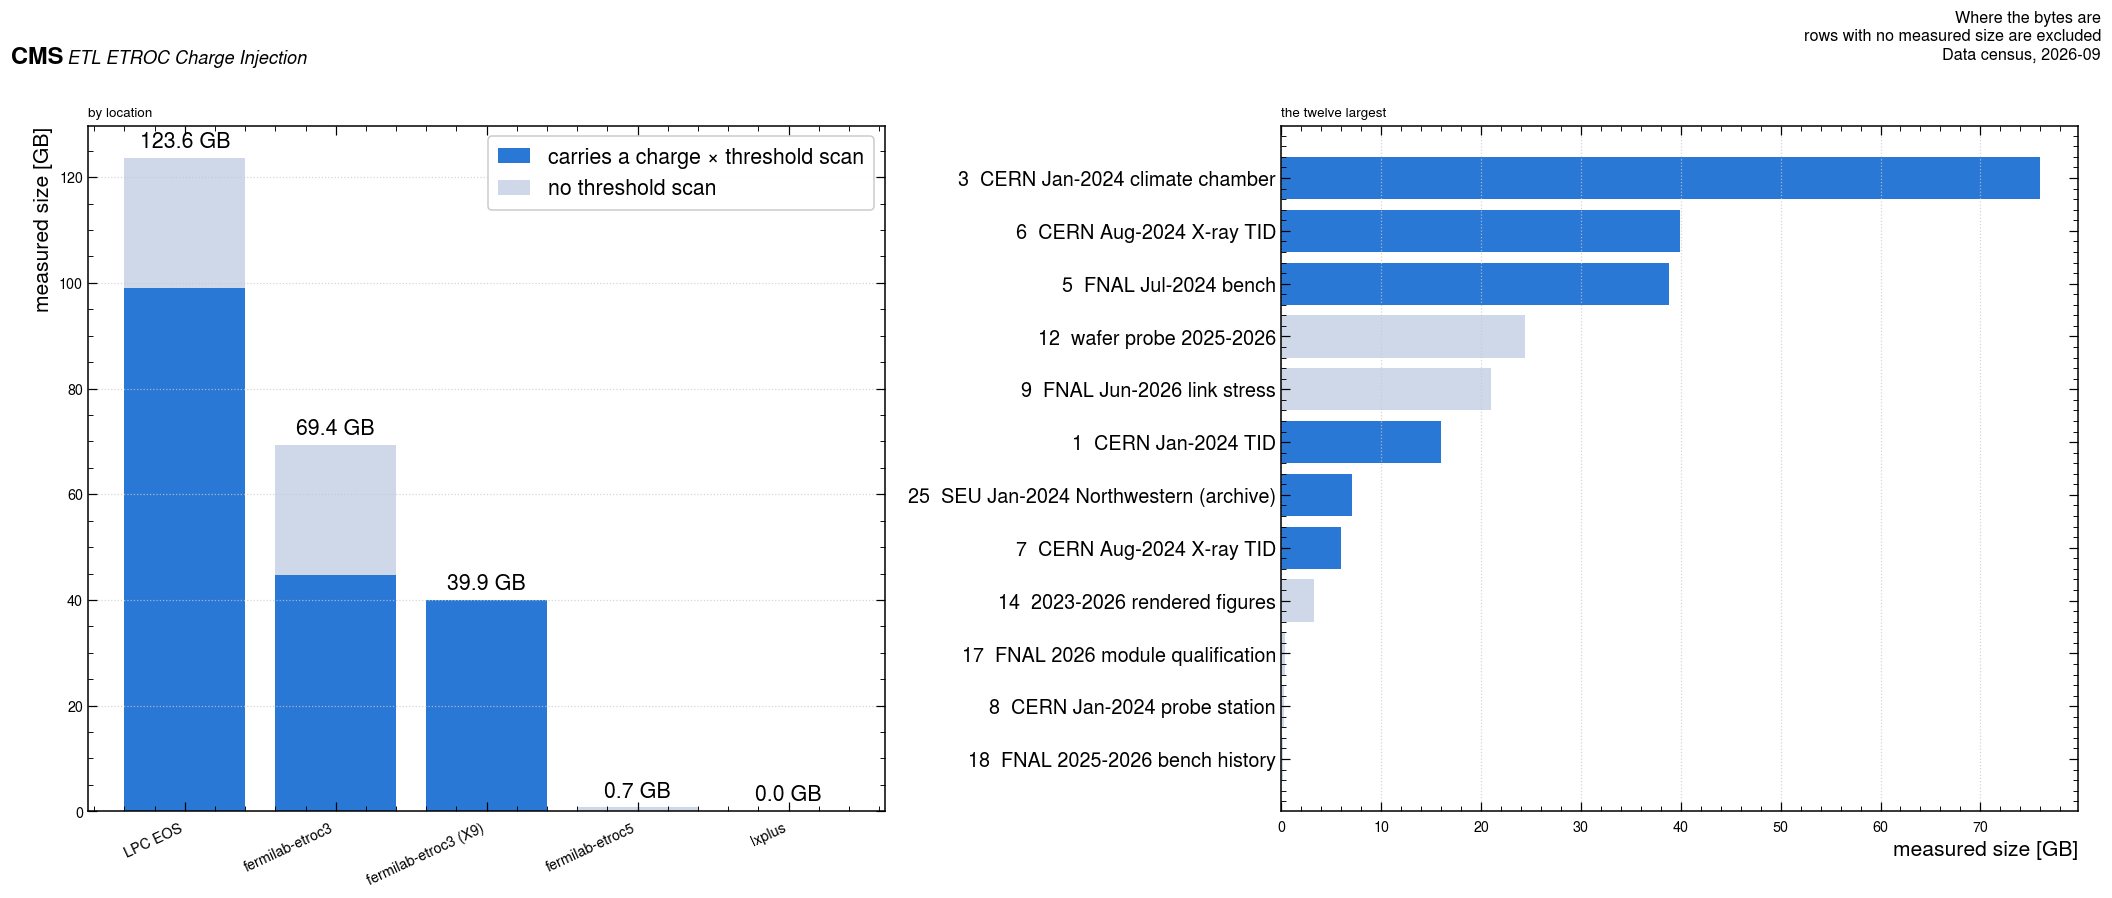

In [9]:
# 5.6  FIGURE 3 — where the bytes are, split by whether the data set carries a threshold scan.
S = T[T.size_GB_num.notna()].copy()
byloc = S.groupby(["loc_bin", S.has_threshold_scan.str.startswith("yes")],
                  observed=True).size_GB_num.sum().unstack(fill_value=0.0)
for c in [True, False]:
    if c not in byloc:
        byloc[c] = 0.0
byloc = byloc.reindex(ORDER).fillna(0.0)

fig, (ax, ax2) = plt.subplots(1, 2, figsize=(19, 7.5))
xs = np.arange(len(byloc))
ax.bar(xs, byloc[True], color=Q.C_BLUE, label="carries a charge × threshold scan")
ax.bar(xs, byloc[False], bottom=byloc[True], color="#cfd8e8", label="no threshold scan")
for i, L in enumerate(byloc.index):
    tot = byloc.loc[L].sum()
    if tot > 0:
        ax.text(i, tot + 2, "%.1f GB" % tot, ha="center", fontsize=14, color=INK)
ax.set_xticks(xs)
ax.set_xticklabels(byloc.index, rotation=25, ha="right")
ax.set_ylabel("measured size [GB]")
ax.set_title("by location", loc="left")
ax.legend(fontsize=14)
ax.grid(axis="x", visible=False)

big = S.sort_values("size_GB_num", ascending=True).tail(12)
cols = [Q.C_BLUE if s.startswith("yes") else "#cfd8e8" for s in big.has_threshold_scan]
ax2.barh(np.arange(len(big)), big.size_GB_num, color=cols)
ax2.set_yticks(np.arange(len(big)))
ax2.set_yticklabels(["%s  %s" % (a, b[:42]) for a, b in zip(big.id, big.campaign)], fontsize=13)
ax2.set_xlabel("measured size [GB]")
ax2.set_title("the twelve largest", loc="left")
ax2.grid(axis="y", visible=False)
fig.tight_layout()
header(fig, "Where the bytes are", tag="rows with no measured size are excluded",
       scale=0.66, y=1.02)
Q.save_fig(fig, "census_fig3_sizes")
plt.show()

## 6. The auxiliary-data matrix

The census above says what was *acquired*. This matrix says what was **monitored while it was
acquired** — and it is the more uncomfortable of the two tables.

Eight kinds of monitoring, one column each: the **low-voltage supply log** (rail voltage *and*
current), the **baseline / noise-width maps** from autocalibration, the **on-chip temperature**
(VTemp — an ambient air or cold-plate reading is not VTemp and is not counted as one), the
**sensor-bias log**, a recorded or decodable **voltage reference**, a **chamber or chiller log**,
a **register dump**, and a human **logbook**.

Five values are used and they mean different things:

* **`yes`** — it exists as data.
* **`partial`** — it exists for part of the campaign, or as something weaker than an instrument
  log (a prose note, a journal field, a single date).
* **`no`** — it was searched for and is not there.
* **`na`** — the question does not arise (a sensor-bias log on a bare die).
* **`unknown`** — **the scan did not check.** This is a hole in the census, not a negative
  result, and it must not be read as `no`.
* **`logged-missing`** — the campaign demonstrably **wrote** the log and the file has **not been
  located**. It no longer appears in the matrix: the one campaign that carried it, the ET2.03 dose
  campaign, had its folder supplied on 2026-09-04 (section 7.7). The value stays in the vocabulary
  because the interval it names is real: an analysis notebook opened five databases by name months
  before anyone could find them. "Recorded, not found" is a
  different statement from "not recorded", and collapsing it into `no` would be wrong in the
  direction that matters.

In [10]:
AUX = Q.load_aux_matrix()
print("aux matrix: %d campaigns x %d monitoring kinds" % (len(AUX), len(Q.AUX_KINDS)))
print()
print(AUX[["campaign", "census_rows"] + Q.AUX_KINDS].to_string(index=False))

aux matrix: 16 campaigns x 8 monitoring kinds

                                                              campaign    census_rows lv_supply_log blnw_maps   vtemp  hv_log vref_record chamber_log register_dump logbook
                                       CERN Jan-2024 TID (bare ET2.01)            1;2       partial       yes      no      na          no          no            no      no
                         CERN Jan-2024 climate chamber (hybrid ET2.01)              3       partial       yes      no      no          no     partial            no      no
                                    DESY May-2025 waveform-sampler run           4;23            no        no      no      no          no          no            no      no
                                            FNAL Jul-2024 ET2.03 bench              5            no   partial      no      na          no          no            no      no
                                        CERN Aug-2024 ET2.03 X-ray TID            6;7        

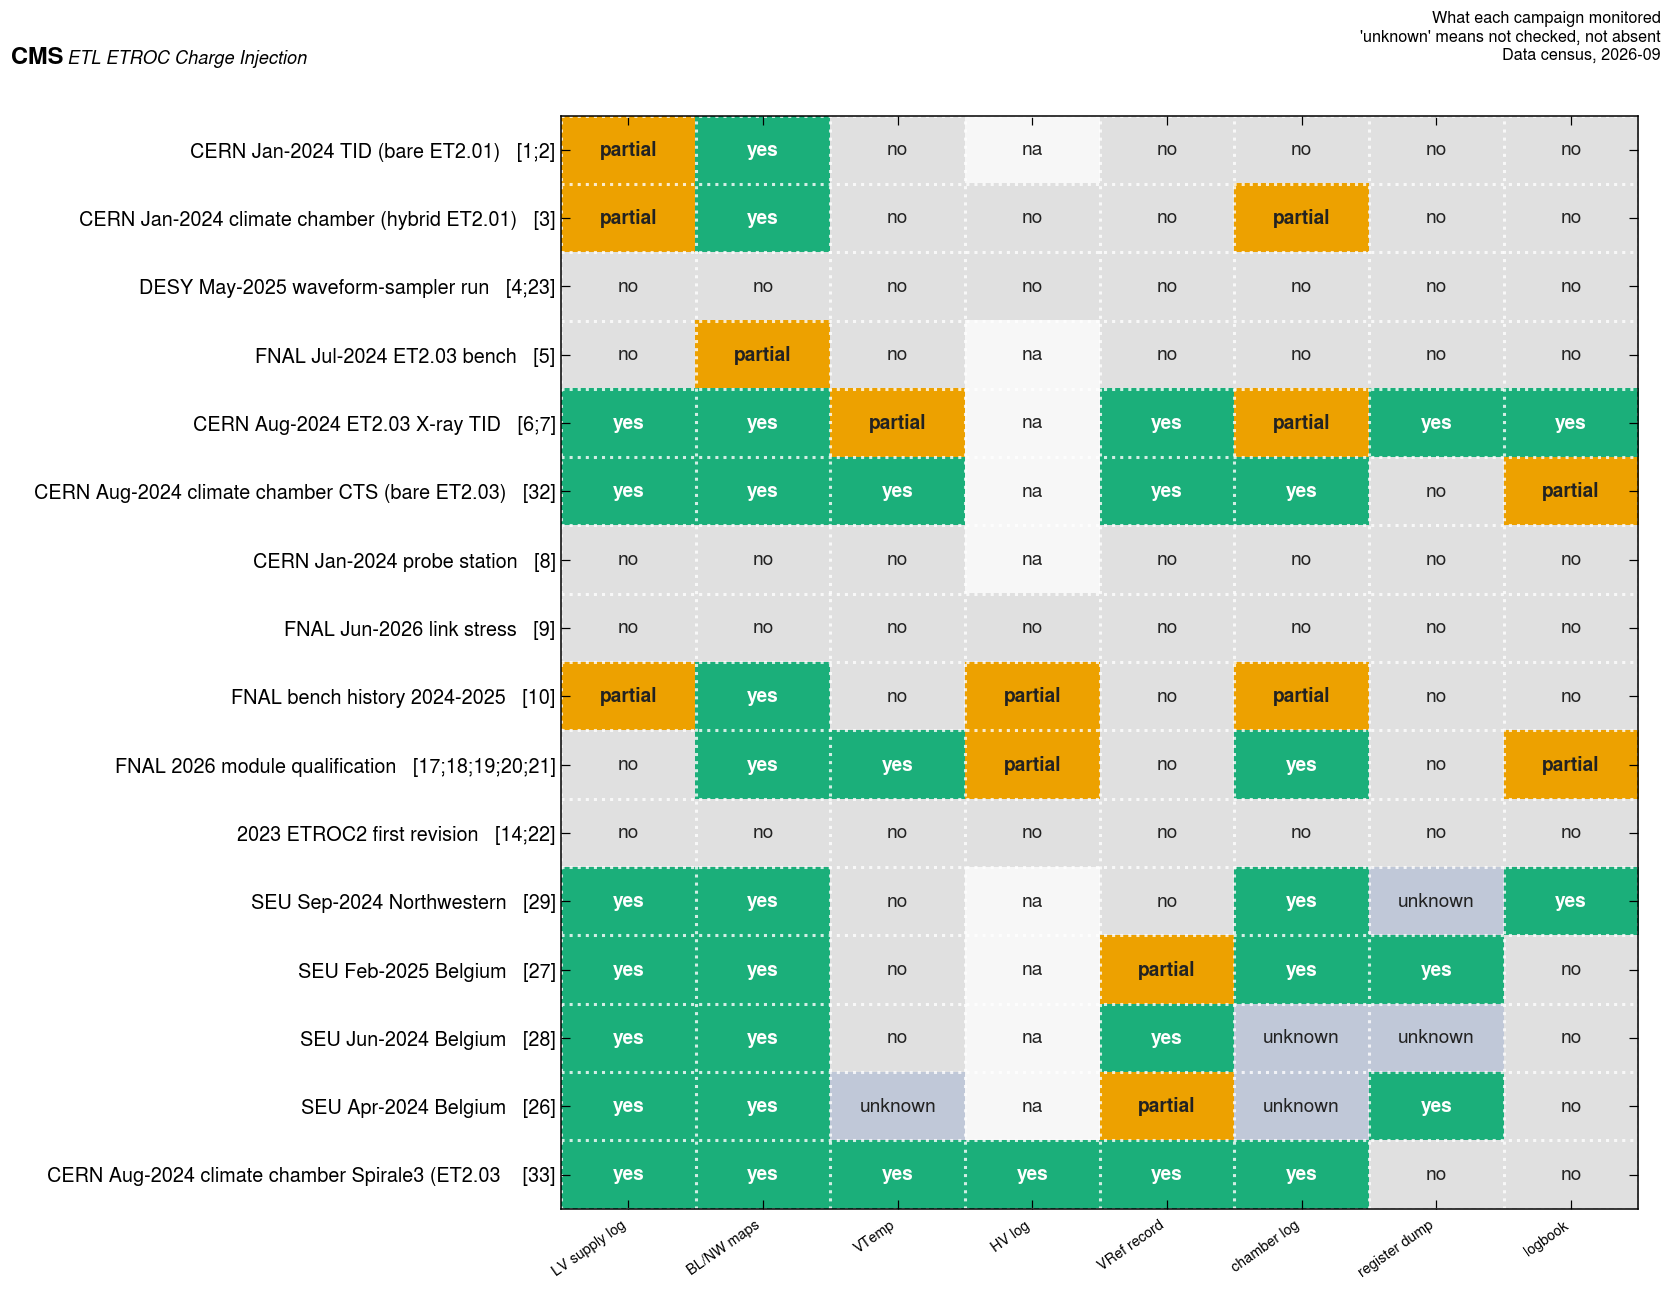

In [11]:
# 6.1  FIGURE 4 — the same matrix as an annotated grid.
vals = AUX[Q.AUX_KINDS].values
code = {v: i for i, v in enumerate(Q.AUX_VALUES)}
grid = np.vectorize(lambda s: code.get(s, code["unknown"]))(vals)
cmap = plt.matplotlib.colors.ListedColormap([Q.AUX_COLOUR[v] for v in Q.AUX_VALUES])

fig, ax = plt.subplots(figsize=(15, 11))
ax.imshow(grid, cmap=cmap, vmin=-0.5, vmax=len(Q.AUX_VALUES) - 0.5, aspect="auto")
for i in range(vals.shape[0]):
    for j in range(vals.shape[1]):
        v = vals[i, j]
        ax.text(j, i, v, ha="center", va="center", fontsize=12.5,
                color="#ffffff" if v in ("yes",) else "#222222",
                fontweight="bold" if v in ("yes", "partial") else "normal")
ax.set_xticks(range(len(Q.AUX_KINDS)))
ax.set_xticklabels([Q.AUX_LABELS[k] for k in Q.AUX_KINDS], rotation=35, ha="right")
ax.set_yticks(range(len(AUX)))
ax.set_yticklabels(["%s   [%s]" % (c[:47], r) for c, r in zip(AUX.campaign, AUX.census_rows)],
                   fontsize=13)
ax.set_xticks(np.arange(-0.5, len(Q.AUX_KINDS)), minor=True)
ax.set_yticks(np.arange(-0.5, len(AUX)), minor=True)
ax.grid(which="minor", color="#ffffff", linewidth=2)
ax.grid(which="major", visible=False)
ax.tick_params(which="minor", length=0)
fig.tight_layout()
header(fig, "What each campaign monitored", tag="'unknown' means not checked, not absent",
       scale=0.66, y=1.02)
Q.save_fig(fig, "census_fig4_aux_matrix")
plt.show()

In [12]:
# 6.2  Count the matrix, so the shape of the problem is a number rather than an impression.
cnt = pd.DataFrame({k: AUX[k].value_counts() for k in Q.AUX_KINDS}).T.fillna(0).astype(int)
cnt = cnt.reindex(columns=[v for v in Q.AUX_VALUES if v in cnt.columns])
cnt.index = [Q.AUX_LABELS[k] for k in cnt.index]
print(cnt.to_string())
print("\nover %d campaigns:" % len(AUX))
for k in Q.AUX_KINDS:
    n_yes = int((AUX[k] == "yes").sum())
    n_part = int((AUX[k] == "partial").sum())
    print("  %-16s %d yes, %d partial" % (Q.AUX_LABELS[k], n_yes, n_part))

               yes  partial  no  na  unknown
LV supply log    7        3   6   0        0
BL/NW maps      11        1   4   0        0
VTemp            3        1  11   0        1
HV log           1        2   4   9        0
VRef record      4        2  10   0        0
chamber log      5        3   6   0        2
register dump    3        0  11   0        2
logbook          2        2  12   0        0

over 16 campaigns:
  LV supply log    7 yes, 3 partial
  BL/NW maps       11 yes, 1 partial
  VTemp            3 yes, 1 partial
  HV log           1 yes, 2 partial
  VRef record      4 yes, 2 partial
  chamber log      5 yes, 3 partial
  register dump    3 yes, 0 partial
  logbook          2 yes, 2 partial


In [13]:
# 6.3  The nineteen per-campaign history folders of the X9 backup disk (section 3.1). Listing only.
X9 = Q.load_x9_history_folders()
X9["sqlite_files"] = X9.sqlite_files.replace("", "— none —")
print("RAW: one `ls` per folder, read-only, 2026-09-04. %d folders.\n" % len(X9))
print(X9.rename(columns={"n_entries": "entries", "n_csv": "csv"})
      .to_string(index=False, max_colwidth=88))
has = X9.sqlite_files.str.contains("PowerHistory")
print("\nDERIVED: %d of %d folders carry a PowerHistory (rail) log, %d a ti1080 (ambient) log,"
      % (int(has.sum()), len(X9), int(X9.sqlite_files.str.contains("ti1080").sum())))
print("         %d an ADCHistory (the table that holds VTemp and, elsewhere, vref),"
      % int(X9.sqlite_files.str.contains("ADCHistory").sum()))
print("         %d a vol_monitoring (the only direct VRef log anywhere): %s."
      % (int(X9.sqlite_files.str.contains("vol_monitoring").sum()),
         ", ".join(X9[X9.sqlite_files.str.contains("vol_monitoring")].folder)))
print("\nNone of these campaigns is analysed in this folder. There is no CERN_Aug_2024_TID_history")
print("folder on this disk; it was supplied separately and now lives on LPC EOS — see section 7.7.")

RAW: one `ls` per folder, read-only, 2026-09-04. 19 folders.

                    folder  entries  csv                                                                             sqlite_files                 subdirs
            BelgiumFeb2025        8    0 BaselineHistory;InvalidFCCounterHistory;PowerHistory_v2;ti1080_sensor_data;and a pre_...                        
           BelgiumJune2024        1    0                                                                          BaselineHistory                        
      CERN_Aug_2024_CC_CTS      107  102                        BaselineHistory;PowerHistory_v2;ti1080_sensor_data;vol_monitoring               csv_files
 CERN_Aug_2024_TB_Suitcase      197  192 ADCHistory_testboard;BaselineHistory;PowerHistoryHV_v2;PowerHistory_v2;ti1080_sensor_...                        
CERN_Sept_2024_TB_Suitcase      293  288 ADCHistory_testboard;BaselineHistory;PowerHistoryHV_v2;PowerHistory_v2;ti1080_sensor_...                        
     CERN_Suit

## 7. The auxiliary data itself

Notebook 02 already plots the climate-chamber campaign's own supply rails and its baseline
history (`figures/hyb_aux1_lv_rails.*` and `figures/hyb_aux2_baseline_history.*`), so this
notebook does not repeat them. What follows is everything else the matrix marks `yes` or
`partial` that no other notebook here shows.

### 7.1 The CERN January-2024 TID campaign had a supply log, and it has never been read

Three `PowerHistory_v2.sqlite` files sit inside the TID tree on LPC EOS, in the 2024-01-10,
2024-01-12 and 2024-01-14 day directories. Between them they hold **231 120 samples** of the
analog and digital rail **voltage and current** at about 5 s, alongside the bare-die money plot
that notebook 01 analyses. Nothing in this folder, and nothing found by either scan, has ever
used them.

The extraction keeps one sample per rail per minute; it reproduces every per-day median current
of the full tables to within 0.0001 A (`data/census/PROVENANCE.md`).

In [14]:
LV = Q.load_tid_lv()
ACT = Q.load_tid_lv_actions()
print("LV series: %d rows, %s -> %s" % (len(LV), LV.timestamp.min(), LV.timestamp.max()))
print("rails:", sorted(LV.rail.unique()), " source files:", sorted(LV.source_file.unique()))
print("\nthe logger's own Start/Stop rows (RAW):")
print(ACT.to_string(index=False))
print("\nsamples below 0.5 V (the rail was off) — kept in the series, excluded from medians:")
off = LV[LV.V <= 0.5]
print("  %d of %d, all on %s, rail %s"
      % (len(off), len(LV), sorted(off.day.unique()), sorted(off.rail.unique())))

LV series: 19268 rows, 2024-01-10 22:40:43.260260 -> 2024-01-19 06:53:02.297054
rails: ['Analog', 'Digital']  source files: ['ph_2024-01-10.sqlite', 'ph_2024-01-12.sqlite', 'ph_2024-01-14.sqlite']

the logger's own Start/Stop rows (RAW):
         source_file                  timestamp system    type message
ph_2024-01-10.sqlite 2024-01-10 22:40:38.256038  Power Logging   Start
ph_2024-01-10.sqlite 2024-01-11 00:27:54.467337  Power Logging    Stop
ph_2024-01-12.sqlite 2024-01-12 16:02:32.247005  Power Logging   Start
ph_2024-01-12.sqlite 2024-01-14 22:02:49.920801  Power Logging    Stop
ph_2024-01-14.sqlite 2024-01-14 22:12:30.186369  Power Logging    Stop
ph_2024-01-14.sqlite 2024-01-14 22:15:37.933756  Power Logging   Start
ph_2024-01-14.sqlite 2024-01-22 18:00:21.372171  Power Logging    Stop

samples below 0.5 V (the rail was off) — kept in the series, excluded from medians:
  6 of 19268, all on ['2024-01-14'], rail ['Analog']


**Which day sat at which condition.** The campaign wrote its dose and plate temperature into
every scan-directory name as a suffix (`..._QInj_15_m25c_400MRad`). Parsing all eleven day
directories of the tree on LPC EOS on 2026-09-04 gives, per day, the tag and the number of scan
directories of each kind:

| day | scan directories | dose tag |
|---|---|---|
| 2024-01-04 | none (BL/NW maps only) | — |
| 2024-01-05 | 12 TDC + 7 TurnOff + 2 NoiseOnly, **chip `Pair1`, DAC 48-59** | none |
| 2024-01-10 | 17 TurnOff + 16 NoiseOnly + **12 `BinarySearch_TurnOn`** | none |
| 2024-01-11 | 7 856 TDC + 72 TurnOff + 12 NoiseOnly | **none = pre-irradiation** |
| 2024-01-11 `_PlateTemp12C_DryAir` | identical listing, 4.9 GB — **the same day stored twice** | none |
| 2024-01-12 | 72 TurnOff + 24 NoiseOnly | **`m25c_0MRad`** |
| 2024-01-14 | none (the two sqlite logs only) | — |
| 2024-01-15 | 4 535 TDC + 72 TurnOff + 12 NoiseOnly | **`m25c_200MRad`** |
| 2024-01-16 | 3 314 TDC | **`m25c_200MRad`** |
| 2024-01-18 | 3 481 TDC + 72 TurnOff + 12 NoiseOnly | **`m25c_400MRad`** |
| 2024-01-19 | 4 230 TDC | **`m25c_400MRad`** |

The `BinarySearch_TurnOn` directories on 2024-01-10 are a **fourth scan kind** that neither scan
recorded — a discriminator search with no injection, twelve of them, one per pixel. They are not
charge-injection points and they change nothing in the census, but the kind exists.

Two of those lines are corrections to what the census documents recorded, and both are folded
into `qinj_census.csv`:

* The **2024-01-11 day is stored twice**, under a plain name and under a `_PlateTemp12C_DryAir`
  name, with identical listings and 4.9 GB each. The scan-directory total of 31 284 counts both
  copies, so **4.9 GB of the tree's 16 GB is a duplicate.**
* The **DAC 48-59 scans of 2024-01-05 are on chip `Pair1`**, not on `ET2p01_W36_6`. That matters
  because the archive of row 25 was reported as reaching a DAC floor of 48 on `ET2p01_W36_6`
  against a floor of 435 elsewhere; the low-DAC directories that exist in this tree belong to a
  different chip on a day that scanned one pixel at one charge. The most likely reading is that
  row 25's quoted range is aggregated across chips. It is **not** evidence of an unseen low-
  threshold extension of the bare-die sweep.

The mapping used below is `qinj_common.TID_LV_DAY`, and it labels its own provenance: the six
scan days take their condition from the directory tags above; the four days with an auxiliary
log and no scan take theirs from the surrounding days and are marked `between-days`.

In [15]:
day = pd.DataFrame(Q.TID_LV_DAY).T.rename_axis("day").reset_index()
med = (LV[LV.V > 0.5].groupby(["day", "rail"])
       .agg(n=("I_A", "size"), V_median=("V", "median"), I_median=("I_A", "median"))
       .round(4).reset_index())
tab = med.pivot(index="day", columns="rail", values=["V_median", "I_median", "n"])
tab.columns = ["%s %s" % (a.replace("_median", ""), b) for a, b in tab.columns]
tab = day.set_index("day").join(tab)
print(tab[["dose", "temp", "scans", "cond_source", "n Analog",
           "V Analog", "I Analog", "V Digital", "I Digital"]].to_string())
print("\nDERIVED. Medians over powered samples only (V > 0.5 V). 'n' is the kept samples per rail.")

           dose temp                                  scans                         cond_source  n Analog  V Analog  I Analog  V Digital  I Digital
day                                                                                                                                                
2024-01-10    0   12  17 TurnOff + 16 NoiseOnly + 12 TurnOn  untagged; by continuity with 01-11      80.0    1.2380    0.3382      1.216     0.1168
2024-01-11    0   12                  7856 TDC + 72 TurnOff                     directory names      28.0    1.2380    0.3379      1.216     0.1166
2024-01-12    0  -25                             72 TurnOff                     directory names     478.0    1.2670    0.4665      1.214     0.1079
2024-01-13    0  -25                                   none                        between-days    1440.0    1.2660    0.4630      1.213     0.1072
2024-01-14    0  -25                                   none                        between-days    1428.0    1.2

Analog: 1 line breaks at ['01-12 16:02']
Digital: 1 line breaks at ['01-12 16:02']


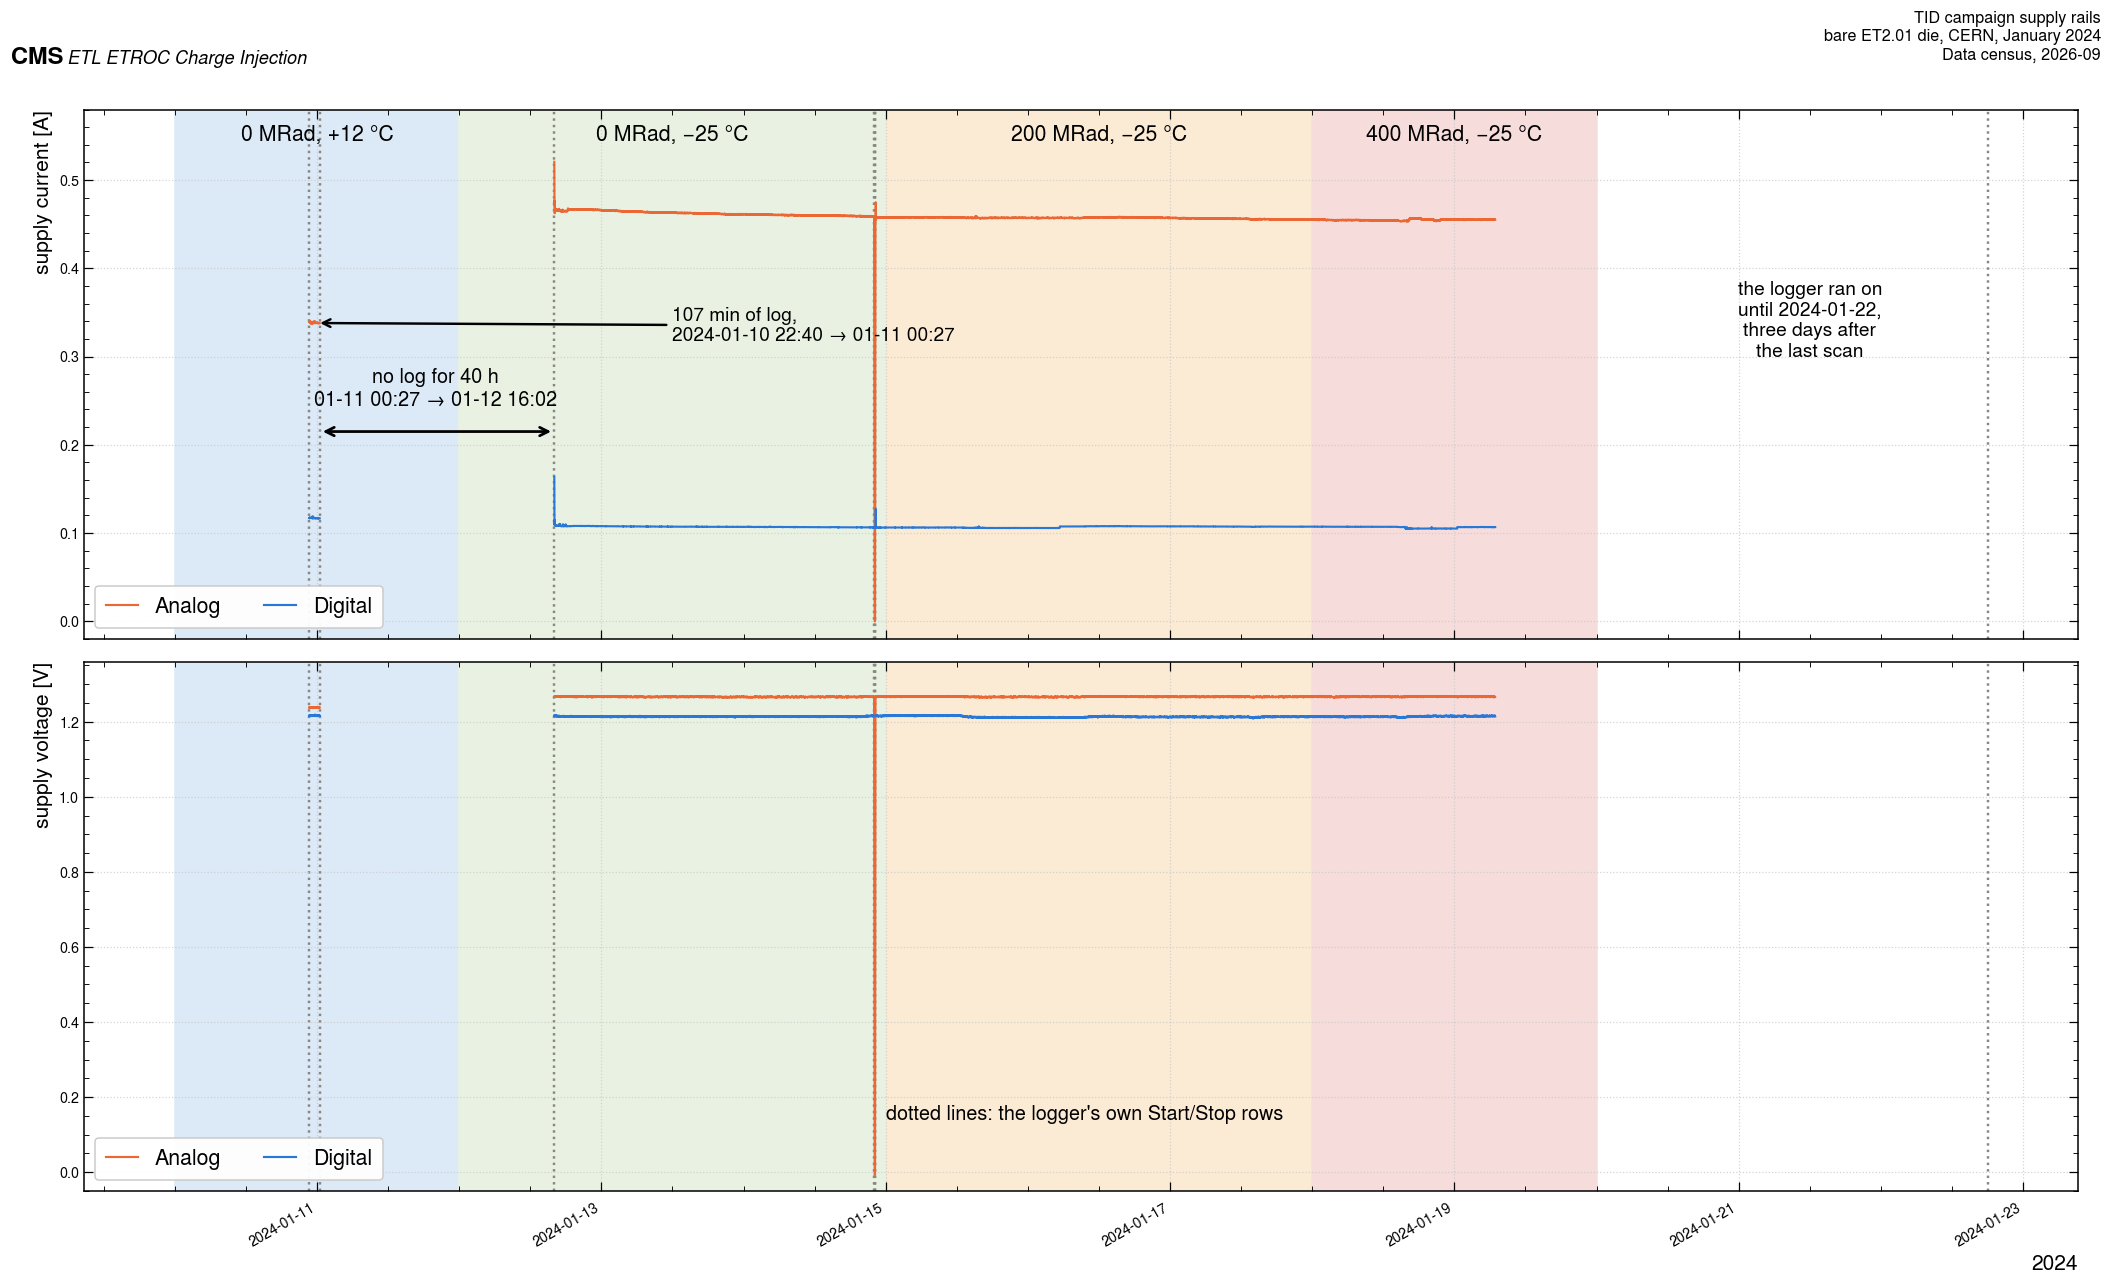

In [16]:
# 7.1b  FIGURE 5 — the rails against time, with the campaign's conditions drawn on.
on = LV[LV.V > 0.5]
BLOCKS = [("0 MRad, +12 °C", "2024-01-10", "2024-01-12", "#dce9f7"),
          ("0 MRad, −25 °C", "2024-01-12", "2024-01-15", "#e9f2e2"),
          ("200 MRad, −25 °C", "2024-01-15", "2024-01-18", "#fbead4"),
          ("400 MRad, −25 °C", "2024-01-18", "2024-01-20", "#f7dcdc")]

fig, axes = plt.subplots(2, 1, figsize=(19, 11), sharex=True)
for ax in axes:
    for lab, a, b, c in BLOCKS:
        ax.axvspan(pd.Timestamp(a), pd.Timestamp(b), color=c, zorder=0)
for lab, a, b, c in BLOCKS:
    axes[0].text(pd.Timestamp(a) + (pd.Timestamp(b) - pd.Timestamp(a)) / 2, 0.545, lab,
                 ha="center", fontsize=14, color=INK)
for rail, col in [("Analog", Q.C_ORANGE), ("Digital", Q.C_BLUE)]:
    s = LV[LV.rail == rail].sort_values("timestamp").copy()
    # Break the line wherever the logger stopped for more than ten minutes, so that the
    # 40-hour hole between 2024-01-11 and 01-12 is drawn as a hole and not as a ramp.
    brk = s.timestamp.diff() > pd.Timedelta(minutes=10)
    s.loc[brk, ["I_A", "V"]] = np.nan
    axes[0].plot(s.timestamp, s.I_A, color=col, lw=1.4, label=rail)
    axes[1].plot(s.timestamp, s.V, color=col, lw=1.4, label=rail)
    print("%s: %d line breaks at %s" % (rail, int(brk.sum()),
                                        list(s.timestamp[brk].dt.strftime("%m-%d %H:%M"))))
for _, a in ACT.iterrows():
    for ax in axes:
        ax.axvline(a.timestamp, color=Q.GREY, ls=":", lw=1.6, zorder=1)
axes[0].text(pd.Timestamp("2024-01-11 20:00"), 0.245,
             "no log for 40 h\n01-11 00:27 → 01-12 16:02", fontsize=13, color=INK,
             ha="center")
axes[0].annotate("", xy=(pd.Timestamp("2024-01-12 16:02"), 0.215),
                 xytext=(pd.Timestamp("2024-01-11 00:27"), 0.215),
                 arrowprops=dict(arrowstyle="<->", lw=1.8, color=INK))
axes[0].annotate("107 min of log,\n2024-01-10 22:40 → 01-11 00:27",
                 xy=(pd.Timestamp("2024-01-11 00:00"), 0.338),
                 xytext=(pd.Timestamp("2024-01-13 12:00"), 0.335), fontsize=12.5, color=INK,
                 arrowprops=dict(arrowstyle="->", lw=1.6, color=INK), va="center")
axes[0].text(pd.Timestamp("2024-01-21 12:00"), 0.30,
             "the logger ran on\nuntil 2024-01-22,\nthree days after\nthe last scan",
             fontsize=12.5, color=INK, ha="center")
axes[0].set_ylabel("supply current [A]")
axes[0].set_ylim(-0.02, 0.58)
axes[1].set_ylabel("supply voltage [V]")
axes[1].set_ylim(-0.05, 1.36)
axes[1].set_xlabel("2024")
for ax in axes:
    ax.legend(loc="lower left", fontsize=14, ncol=2)
axes[1].text(pd.Timestamp("2024-01-15"), 0.14,
             "dotted lines: the logger's own Start/Stop rows", fontsize=13, color=INK)
fig.autofmt_xdate()
fig.tight_layout()
header(fig, "TID campaign supply rails", tag="bare ET2.01 die, CERN, January 2024",
       scale=0.66, y=1.015)
Q.save_fig(fig, "census_fig5_tid_lv_rails")
plt.show()

 dose_MRad  temp_C    rail    n      I     V   I_lo   I_hi
         0     -25  Analog 3346 0.4617 1.266 0.4590 0.4666
         0     -25 Digital 3352 0.1070 1.214 0.1064 0.1080
         0      12  Analog  108 0.3381 1.238 0.3375 0.3394
         0      12 Digital  108 0.1168 1.216 0.1166 0.1172
       200     -25  Analog 4320 0.4572 1.266 0.4554 0.4580
       200     -25 Digital 4320 0.1072 1.213 0.1057 0.1077
       400     -25  Analog 1854 0.4549 1.266 0.4538 0.4565
       400     -25 Digital 1854 0.1068 1.214 0.1050 0.1072


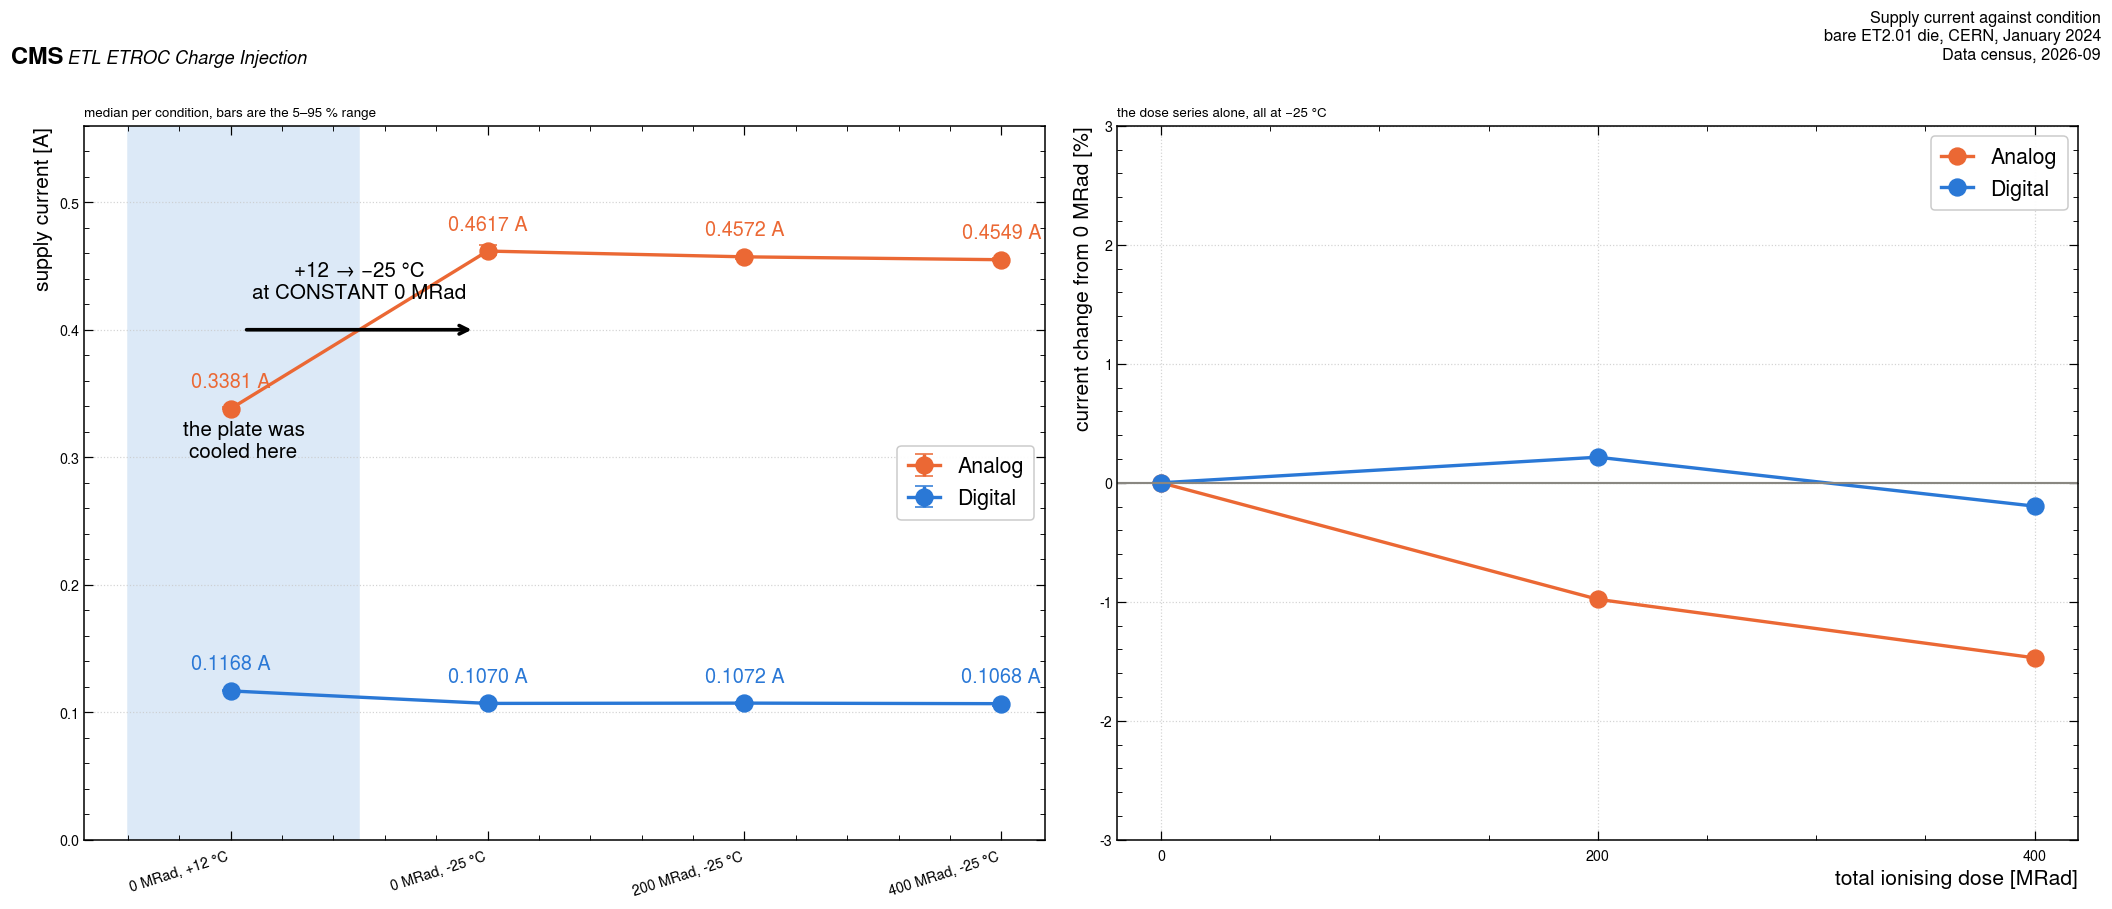

In [17]:
# 7.1c  FIGURE 6 — the same data grouped by the condition the campaign was in.
cond = (on.groupby(["dose_MRad", "temp_C", "rail"])
        .agg(n=("I_A", "size"), I=("I_A", "median"), V=("V", "median"),
             I_lo=("I_A", lambda s: s.quantile(0.05)),
             I_hi=("I_A", lambda s: s.quantile(0.95))).reset_index())
ORDER_C = [(0, 12), (0, -25), (200, -25), (400, -25)]
labels = [Q.cond_label(d, t) for d, t in ORDER_C]
print(cond.round(4).to_string(index=False))

fig, (ax, ax2) = plt.subplots(1, 2, figsize=(19, 7.6))
xs = np.arange(len(ORDER_C))
for rail, col in [("Analog", Q.C_ORANGE), ("Digital", Q.C_BLUE)]:
    y, lo, hi = [], [], []
    for d, t in ORDER_C:
        r = cond[(cond.dose_MRad == d) & (cond.temp_C == t) & (cond.rail == rail)].iloc[0]
        y.append(r.I)
        lo.append(r.I - r.I_lo)
        hi.append(r.I_hi - r.I)
    ax.errorbar(xs, y, yerr=[lo, hi], marker="o", ms=11, lw=2.2, capsize=6,
                color=col, label=rail)
    for x, v in zip(xs, y):
        ax.annotate("%.4f A" % v, (x, v), textcoords="offset points", xytext=(0, 14),
                    ha="center", fontsize=13, color=col)
ax.axvspan(-0.4, 0.5, color="#dce9f7", zorder=0)
ax.text(0.05, 0.30, "the plate was\ncooled here", fontsize=13.5, ha="center", color=INK)
ax.annotate("", xy=(0.95, 0.40), xytext=(0.05, 0.40),
            arrowprops=dict(arrowstyle="->", lw=2.4, color=INK))
ax.text(0.5, 0.425, "+12 → −25 °C\nat CONSTANT 0 MRad", ha="center", fontsize=13.5, color=INK)
ax.set_xticks(xs)
ax.set_xticklabels(labels, rotation=18, ha="right")
ax.set_ylabel("supply current [A]")
ax.set_ylim(0.0, 0.56)
ax.set_title("median per condition, bars are the 5–95 % range", loc="left")
ax.legend(fontsize=14, loc="center right")
ax.grid(axis="x", visible=False)

dosed = [c for c in ORDER_C if c[1] == -25]
for rail, col in [("Analog", Q.C_ORANGE), ("Digital", Q.C_BLUE)]:
    y = [cond[(cond.dose_MRad == d) & (cond.temp_C == t) & (cond.rail == rail)].iloc[0].I
         for d, t in dosed]
    ref = y[0]
    ax2.plot([d for d, _ in dosed], [100 * (v / ref - 1) for v in y], marker="o", ms=11,
             lw=2.2, color=col, label=rail)
ax2.axhline(0, color=Q.GREY, lw=1.4)
ax2.set_xlabel("total ionising dose [MRad]")
ax2.set_ylabel("current change from 0 MRad [%]")
ax2.set_xticks([0, 200, 400])
ax2.set_ylim(-3, 3)
ax2.set_title("the dose series alone, all at −25 °C", loc="left")
ax2.legend(fontsize=14)
fig.tight_layout()
header(fig, "Supply current against condition", tag="bare ET2.01 die, CERN, January 2024",
       scale=0.66, y=1.02)
Q.save_fig(fig, "census_fig6_tid_lv_by_condition")
plt.show()

In [18]:
# 7.1d  The two numbers the figure is about.
def I_at(dose, temp, rail):
    return float(cond[(cond.dose_MRad == dose) & (cond.temp_C == temp)
                      & (cond.rail == rail)].iloc[0].I)


step_a = 100 * (I_at(0, -25, "Analog") / I_at(0, 12, "Analog") - 1)
step_d = 100 * (I_at(0, -25, "Digital") / I_at(0, 12, "Digital") - 1)
dose_a = 100 * (I_at(400, -25, "Analog") / I_at(0, -25, "Analog") - 1)
dose_d = 100 * (I_at(400, -25, "Digital") / I_at(0, -25, "Digital") - 1)
V_before = float(cond[(cond.dose_MRad == 0) & (cond.temp_C == 12)
                      & (cond.rail == "Analog")].iloc[0].V)
V_after = float(cond[(cond.dose_MRad == 0) & (cond.temp_C == -25)
                     & (cond.rail == "Analog")].iloc[0].V)
print("DERIVED, from the medians printed in cell 7.1c:")
print("  the step, 0 MRad +12 °C -> 0 MRad -25 °C : analog %+.1f %%, digital %+.1f %%"
      % (step_a, step_d))
print("  across the whole dose range at -25 °C    : analog %+.1f %%, digital %+.1f %%"
      % (dose_a, dose_d))
print("  the analog supply terminal voltage also moved across the step: %.3f V -> %.3f V (%+.1f %%)"
      % (V_before, V_after, 100 * (V_after / V_before - 1)))
# 2024-01-10 carries no temperature tag of its own; it is grouped with 2024-01-11 above. The step
# does not depend on that grouping, and this is the check rather than the assertion:
only11 = on[(on.day == "2024-01-11") & (on.rail == "Analog")].I_A.median()
both = on[(on.day.isin(["2024-01-10", "2024-01-11"])) & (on.rail == "Analog")].I_A.median()
print("\n  pre-step analog median using 2024-01-11 alone (the day that carries the +12 °C tag):")
print("    %.4f A, against %.4f A using 01-10 and 01-11 together -- a difference of %.4f A."
      % (only11, both, abs(only11 - both)))
step_only11 = 100 * (I_at(0, -25, "Analog") / only11 - 1)
print("    Restricting to the tagged day moves the step from %+.2f %% to %+.2f %% -- a change of"
      % (step_a, step_only11))
print("    %.2f percentage points, so the grouping does not carry the result."
      % abs(step_only11 - step_a))

DERIVED, from the medians printed in cell 7.1c:
  the step, 0 MRad +12 °C -> 0 MRad -25 °C : analog +36.6 %, digital -8.4 %
  across the whole dose range at -25 °C    : analog -1.5 %, digital -0.2 %
  the analog supply terminal voltage also moved across the step: 1.238 V -> 1.266 V (+2.3 %)

  pre-step analog median using 2024-01-11 alone (the day that carries the +12 °C tag):
    0.3379 A, against 0.3381 A using 01-10 and 01-11 together -- a difference of 0.0002 A.
    Restricting to the tagged day moves the step from +36.56 % to +36.62 % -- a change of
    0.06 percentage points, so the grouping does not carry the result.


### What is, and is not, established by that

**Established.** The analog rail current steps by about a third — the cell above prints the exact
figure — between the two logged blocks either side of the 40-hour gap, while the digital rail
moves the other way by a few per cent. The step is real, it is far outside the sample-to-sample
spread, and it is logged at 5 s alongside the bare-die money plot.

**Also established, and it is the point of this section: the step is not a dose effect.** Both
sides of it are at **0 MRad**. The block before it is the 2024-01-11 pre-irradiation day, whose
scan directories carry no dose tag; the block after it is 2024-01-12, whose 72 turn-off
directories are tagged `m25c_0MRad`. The chip had received no dose on either side. Across the
dose series proper — 0 → 200 → 400 MRad, all at −25 °C, all inside one continuously logged
stretch — the analog current changes by the small percentage printed above, and monotonically
downward.

**Not established: what did cause it.** Three things changed at once across the gap and the log
cannot separate them:

1. the cold plate went from **+12 °C to −25 °C** (the earlier block is the `PlateTemp12C_DryAir`
   day, the later one is `m25c`);
2. the **analog supply terminal voltage itself moved**, by the amount printed above — so it was
   not the same electrical configuration, and a fraction of the current change is simply that;
3. there is a **40-hour hole in the log** across which the chip was recalibrated and the setup
   reworked, and no record says what else was touched.

The honest statement is therefore: **a ~37 % analog-current step is present in this campaign's
supply log, it coincides with the cooldown and a supply change, and it does not coincide with
any dose step.** Reading it as radiation damage requires evidence this campaign does not contain.
The dose dependence that *is* measurable here is the small monotonic decline in the right-hand
panel of figure 6, which is the opposite sign to what "current rises with dose" would predict.

Two further limits, both from the log itself. The rails read back at about 1.27 V rather than
1.2 V, so these are **supply-terminal values including the cable drop**, not on-chip rails. And
the logger has no other channel: `Instrument` is the constant `'Power'` and only `Analog` and
`Digital` ever appear, so there is **no high-voltage, chiller or temperature channel in these
files at all**. The campaign's plate temperature exists only as the `m25c` / `PlateTemp12C`
token in a directory name.

### 7.2 The TID campaign's entire baseline log is 23 minutes

The same tree holds `BaselineHistory_TID_Jan2024_CERN.sqlite`, which the census documents did not
record. It is not a history: it is two full-array autocalibration repeats taken back to back on
one evening.

In [19]:
BLH = Q.load_tid_bl_history()
print("RAW: %d rows, chip %s, %s -> %s"
      % (len(BLH), BLH.chip_name.unique(), BLH.timestamp.min(), BLH.timestamp.max()))
print("columns:", list(BLH.columns), "-- no HV column, no temperature column")
g = BLH.groupby("note").agg(pixels=("baseline", "size"), BL_mean=("baseline", "mean"),
                            BL_std=("baseline", "std"), NW_mean=("noise_width", "mean"),
                            first=("timestamp", "min"), last=("timestamp", "max"))
print()
print(g.round(2).to_string())
span = (BLH.timestamp.max() - BLH.timestamp.min()).total_seconds() / 60
print("\nDERIVED: the whole log spans %.0f minutes of a campaign that ran from 2024-01-04 to 01-19."
      % span)
print("It is dated 2024-01-14, between the 0 MRad and 200 MRad scan days, and the note calls it")
print("'postTID_overnight_BL_test'. Its two repeats agree to %.2f DAC on the array mean."
      % abs(g.BL_mean.iloc[0] - g.BL_mean.iloc[1]))

RAW: 1024 rows, chip ['ET2p01_W36_6'], 2024-01-14 22:23:36.934001 -> 2024-01-14 22:46:04.389858
columns: ['row', 'col', 'baseline', 'noise_width', 'timestamp', 'chip_name', 'note'] -- no HV column, no temperature column

                                pixels  BL_mean  BL_std  NW_mean                      first                       last
note                                                                                                                  
Run0_postTID_overnight_BL_test     512   532.14   13.55     3.67 2024-01-14 22:23:36.934001 2024-01-14 22:40:24.935588
Run1_postTID_overnight_BL_test     512   532.15   13.72     3.70 2024-01-14 22:29:16.456691 2024-01-14 22:46:04.389858

DERIVED: the whole log spans 22 minutes of a campaign that ran from 2024-01-04 to 01-19.
It is dated 2024-01-14, between the 0 MRad and 200 MRad scan days, and the note calls it
'postTID_overnight_BL_test'. Its two repeats agree to 0.01 DAC on the array mean.


### 7.3 The ET2.03 August-2024 TID campaign: a register dump, and nothing else

The ET2.03 dose series (rows 6 and 7) is the ET2.01 series' counterpart on the later revision.
**Nothing in its own data tree records its conditions except the directory names**
(`ET2p03_BARE9_0p95VD_1p20VA_m23p6C_400MRad_44h00m00s_10fC`), which are **supply settings with no
currents and no time series**, plus two 1.7 kB prose files.

That is a statement about the data tree, and section 7.7 shows it is **not** a statement about the
campaign: the rails, the on-chip temperature and the voltage reference were all logged at the
time, into a separate history folder that this census has not been able to locate. Read this
section as what is in hand, not as what was measured.

What it does have, and the ET2.01 campaigns do not, is a **register read-back**: three
`ChipConfig/*.pckl` dumps of the full ETROC2 address space, taken on 2024-08-08, -14 and -21,
decoded through the register map.

In [20]:
CC = Q.load_et2p03_chipconfig()
FIELDS = ["VrefGen_PD", "RefStrSel", "TS_PD", "CLKSel", "PLL_BiasGen_CONFIG",
          "chargeInjectionDelay", "PLL_ENABLEPLL", "singlePort", "serRateLeft"]
show = CC[["file"] + FIELDS].copy()
show["file"] = show.file.str.slice(0, 46)
print("RAW, decoded: %d register dumps x %d decoded fields (plus PeriCfg0..31 raw bytes)"
      % (CC.shape[0], CC.shape[1] - 35))
print()
print(show.to_string(index=False))
print()
ident = [f for f in FIELDS if CC[f].nunique() == 1]
print("fields identical across all three dumps:", ", ".join(ident))
print("PeriCfg3 raw byte:", CC.PeriCfg3_raw.unique(), " PeriCfg6 raw byte:", CC.PeriCfg6_raw.unique())

RAW, decoded: 3 register dumps x 100 decoded fields (plus PeriCfg0..31 raw bytes)

                                          file  VrefGen_PD  RefStrSel  TS_PD  CLKSel  PLL_BiasGen_CONFIG  chargeInjectionDelay  PLL_ENABLEPLL  singlePort  serRateLeft
2024-08-08T17-19-32.363256_ET2p03_BARE9_200MRa           0          3      0       1                   8                    10              1           1            0
2024-08-14T21-21-53.136935_ET2p03_BARE7_0MRad_           0          3      0       1                   8                    10              1           1            0
2024-08-21T09-34-39.431682_ET2p03_BARE7_x_MRad           0          3      0       1                   8                    10              1           1            0

fields identical across all three dumps: VrefGen_PD, RefStrSel, TS_PD, CLKSel, PLL_BiasGen_CONFIG, chargeInjectionDelay, PLL_ENABLEPLL, singlePort, serRateLeft
PeriCfg3 raw byte: [56]  PeriCfg6 raw byte: [3]


**`VrefGen_PD = 0`** (the field is active-high power-down) says the **on-chip voltage-reference
generator was powered up**, identically on all three dumps and on both dies. **`RefStrSel = 3`**
is the reference-strobe selection. **`TS_PD = 0`** says the on-chip temperature sensor was
powered up too — and that is the whole of it, because **no VTemp reading is stored anywhere in
this campaign.** The sensor was on and nobody read it.

RAW: ET2p03_BARE9, 2024-08-03_Array_Test_Results, 256 pixels

 row  col  baseline_DAC  noise_width_DAC
   0    0         822.0              3.0
   0   14         828.0              4.0
   3    0         824.0              5.0
   3   14         834.0              4.0
  12    0         831.0              5.0
  12   14         849.0              4.0

whole array: BL 837.5 +- 10.4 DAC (min 811, max 867), NW 4.10 +- 1.04 DAC


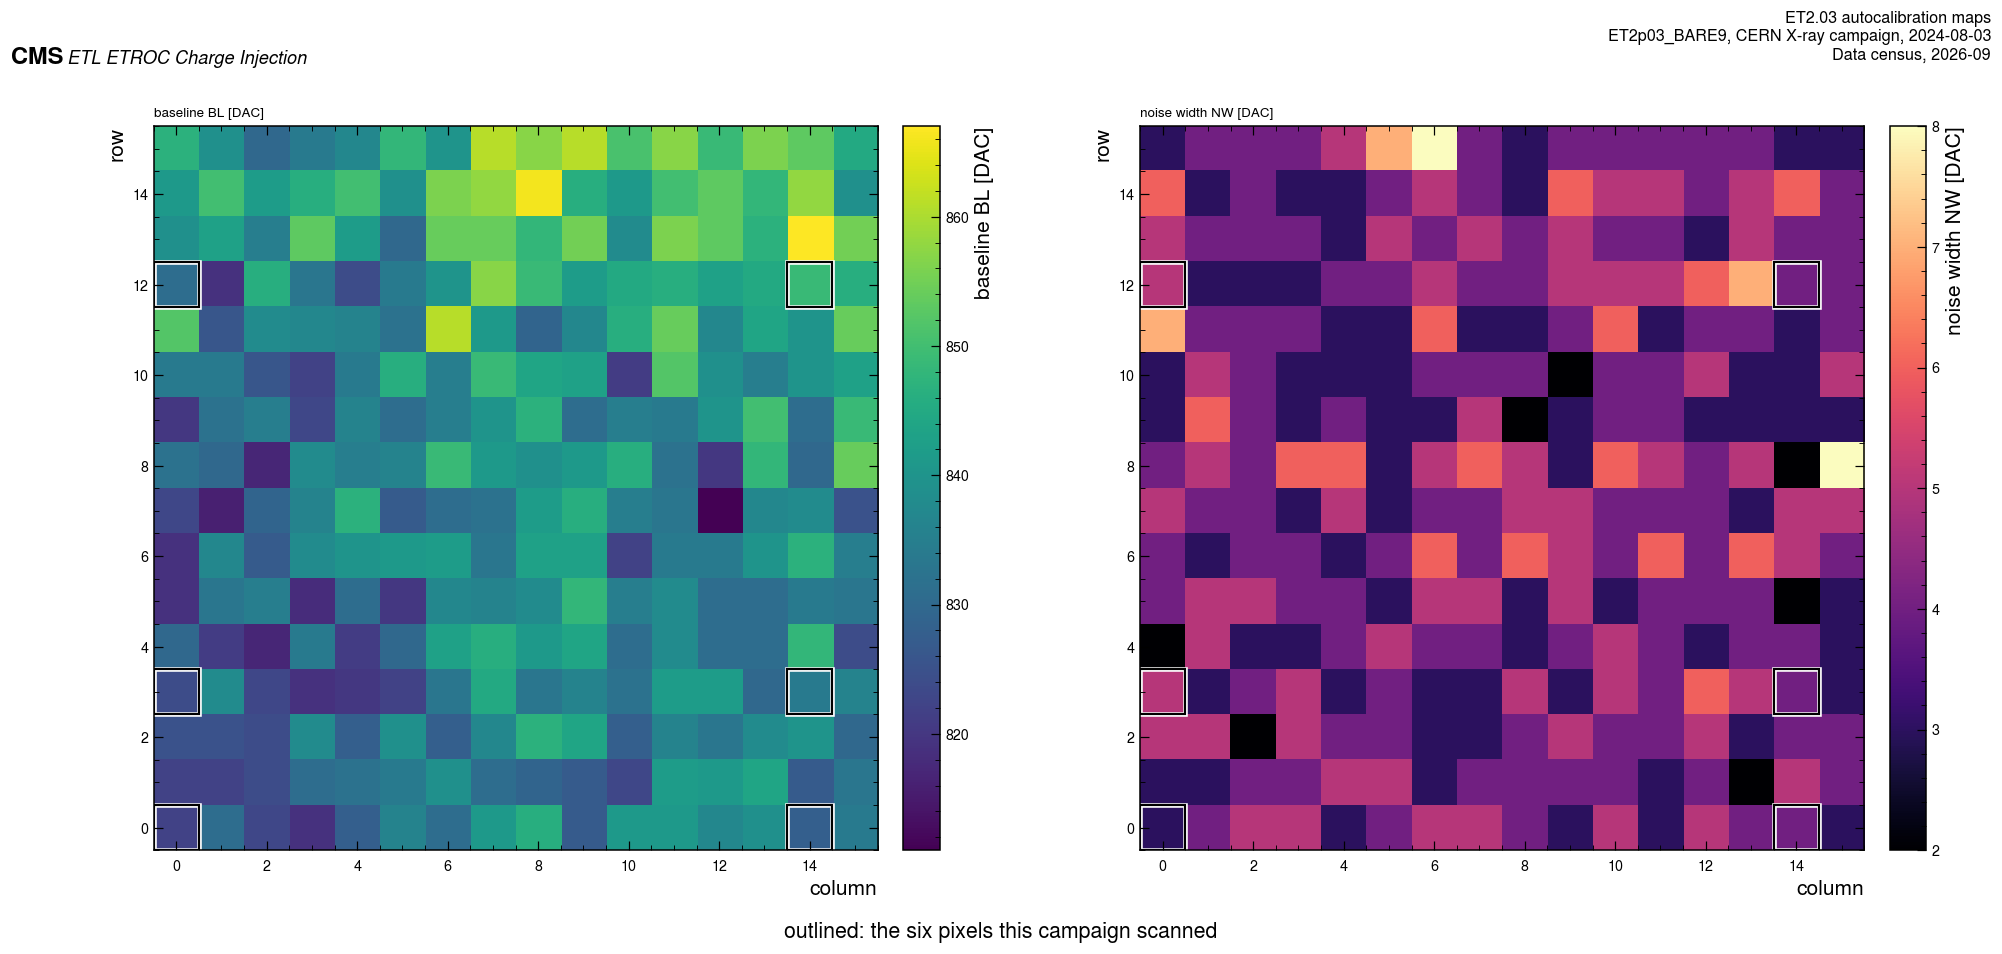

In [21]:
# 7.3b  FIGURE 7 — the ET2.03 autocalibration maps, and the six pixels the campaign scanned.
BN = Q.load_et2p03_blnw()
SCANNED = [(0, 0), (0, 14), (3, 0), (3, 14), (12, 0), (12, 14)]
print("RAW: %s, %s, %d pixels" % (BN.chip.unique()[0], BN.source.unique()[0], len(BN)))
sel = BN[[(r, c) in SCANNED for r, c in zip(BN.row, BN.col)]].sort_values(["row", "col"])
print()
print(sel[["row", "col", "baseline_DAC", "noise_width_DAC"]].to_string(index=False))
print("\nwhole array: BL %.1f +- %.1f DAC (min %d, max %d), NW %.2f +- %.2f DAC"
      % (BN.baseline_DAC.mean(), BN.baseline_DAC.std(), BN.baseline_DAC.min(),
         BN.baseline_DAC.max(), BN.noise_width_DAC.mean(), BN.noise_width_DAC.std()))

fig, axes = plt.subplots(1, 2, figsize=(18, 7.6))
for ax, col, lab, cm in [(axes[0], "baseline_DAC", "baseline BL [DAC]", "viridis"),
                         (axes[1], "noise_width_DAC", "noise width NW [DAC]", "magma")]:
    grid = BN.pivot(index="row", columns="col", values=col).values
    im = ax.imshow(grid, origin="lower", cmap=cm, aspect="equal")
    fig.colorbar(im, ax=ax, fraction=0.046, pad=0.03, label=lab)
    for r, c in SCANNED:
        ax.add_patch(mpatches.Rectangle((c - 0.5, r - 0.5), 1, 1, fill=False,
                                        edgecolor="#ffffff", lw=3.0))
        ax.add_patch(mpatches.Rectangle((c - 0.5, r - 0.5), 1, 1, fill=False,
                                        edgecolor=INK, lw=1.4))
    ax.set_xlabel("column")
    ax.set_ylabel("row")
    ax.set_title(lab, loc="left")
    ax.grid(visible=False)
fig.tight_layout()
fig.text(0.5, -0.02, "outlined: the six pixels this campaign scanned",
         ha="center", fontsize=14, color=INK)
header(fig, "ET2.03 autocalibration maps", tag="ET2p03_BARE9, CERN X-ray campaign, 2024-08-03",
       scale=0.66, y=1.02)
Q.save_fig(fig, "census_fig7_et2p03_blnw")
plt.show()

### 7.4 The climate-chamber campaign: partial chamber, no bias log

Notebook 02 plots that campaign's rails and baseline history, so the figures are not repeated
here. The **coverage** statement belongs in the census, and it is `partial` for a specific
reason:

* **Chamber: partial, and it is a journal rather than an instrument.** There is no chamber
  instrument log. What exists is the `note` field of the campaign's baseline sqlite, which
  records the thermal condition in words (`Run#_m25_Jan_17_2024`, `Run#_OvernightWarmup_...`,
  `Run#_22C_CCoff_dooropen_...`) with baselines logged straight through at 3 s. That makes it a
  baseline-versus-temperature data set in its own right, which is why notebook 02 plots it — but
  it is not a temperature record, and there is no reading in degrees anywhere.
* **Sensor bias: no.** Bias appears in directory names (`HV_210`, `HV_0_CablePluggedIn`,
  `HV_off`) and nowhere else. There is no HV channel in the supply log, no HV column in the
  baseline sqlite, and no HV token in any `note` value.
* **And the specific consequence:** the baseline sqlite begins 2024-01-17 11:46, while every
  −25 °C configuration was taken 2024-01-13 to 01-16. **The bias state of the −25 °C hybrid
  sweeps cannot be recovered from anything in the archive.** Notebook 02 carries that as an open
  caveat rather than an assumption, and it is why the confound-free result there is the
  same-day bias bracket rather than the cold data.

### 7.5 What could have been logged, campaign by campaign, and was not

Every entry below is the difference between what the instrument set-up made possible and what
reached a file. It is written as a list of specific missing artefacts rather than as a
complaint, because it is the requirements list for the next campaign.

In [22]:
GAPS = pd.DataFrame([
    dict(campaign="CERN Jan-2024 TID (rows 1, 2)",
         had="analog + digital V and I at 5 s over 6 of 11 days; BL/NW maps; 23 min of baseline log",
         missing="no log on the 4 heaviest scan days; no temperature channel; no on-chip VTemp; "
                 "no dosimetry beyond an MRad token; no injections-per-point; no RFSel"),
    dict(campaign="CERN Jan-2024 climate chamber (row 3)",
         had="analog + digital V and I at 5 s; baseline sqlite from 01-17 with a thermal journal",
         missing="no chamber instrument log; no HV log, so the −25 °C bias state is unrecoverable; "
                 "no VTemp; no RFSel; no power-mode tag on the −25 °C configurations"),
    dict(campaign="FNAL Jul/Aug-2024 ET2.03 (rows 5, 6, 7)",
         had="three register dumps; two BL/NW maps; two prose info.txt files",
         missing="no power log at all, though a logger existed as working code on the bench PC; "
                 "no temperature log; no VTemp although TS_PD = 0 says the sensor was powered; "
                 "no dose log; no injections-per-point; no RFSel"),
    dict(campaign="CERN Jan-2024 probe station (row 8)",
         had="pass/fail lists and the supply's *IDN? string",
         missing="the injected charge itself is not recorded anywhere, nor the chip revision, "
                 "nor any current, nor any threshold sweep"),
    dict(campaign="FNAL Jun-2026 link stress (row 9)",
         had="a run script and a fast-command toml",
         missing="no charge, no threshold, no rails, no temperature — the toml fixes nothing "
                 "about the front end"),
    dict(campaign="FNAL 2026 module qualification (rows 17–21)",
         had="per-run yaml with charge, offset, HV, power_mode and gain_mode; BL/NW with HV; "
             "on-chip VTemp; chamber T and RH at 4 s; sensor IV",
         missing="RFSel; any threshold or charge sweep; and no copy of any of it on EOS at "
                 "either laboratory"),
    dict(campaign="the SEU trees (rows 25–31)",
         had="the largest supply logs in the census, one of them three-rail across eight chips; "
             "decoded register state before, during and after irradiation; a measured VRef plot",
         missing="no threshold scan in any of them except the archive of row 25; and the VRef "
                 "plot and the vref column have still not been opened"),
])
for _, r in GAPS.iterrows():
    print("== %s" % r.campaign)
    print("   had     : %s" % r["had"])
    print("   missing : %s" % r["missing"])
GAPS.to_csv(Q.OUTDIR / "census_monitoring_gaps.csv", index=False)
print("\nwritten: outputs/census_monitoring_gaps.csv")

== CERN Jan-2024 TID (rows 1, 2)
   had     : analog + digital V and I at 5 s over 6 of 11 days; BL/NW maps; 23 min of baseline log
   missing : no log on the 4 heaviest scan days; no temperature channel; no on-chip VTemp; no dosimetry beyond an MRad token; no injections-per-point; no RFSel
== CERN Jan-2024 climate chamber (row 3)
   had     : analog + digital V and I at 5 s; baseline sqlite from 01-17 with a thermal journal
   missing : no chamber instrument log; no HV log, so the −25 °C bias state is unrecoverable; no VTemp; no RFSel; no power-mode tag on the −25 °C configurations
== FNAL Jul/Aug-2024 ET2.03 (rows 5, 6, 7)
   had     : three register dumps; two BL/NW maps; two prose info.txt files
   missing : no power log at all, though a logger existed as working code on the bench PC; no temperature log; no VTemp although TS_PD = 0 says the sensor was powered; no dose log; no injections-per-point; no RFSel
== CERN Jan-2024 probe station (row 8)
   had     : pass/fail lists and the 

### 7.6 The one ET2.03 campaign that monitored everything, and injected no charge

The backup disk of section 3.1 carries a folder called `CERN_Aug_2024_CC_CTS`. It is **row 32** of
the census, and it is the best-instrumented ET2.03 data set anywhere in it:

* the chip is **`ET2p03_BARE4`**, a **bare ET2.03 die** — a sister part to the `BARE9` and `BARE7`
  of rows 6 and 7, not the same die;
* it ran in the CERN climate chamber from **2024-08-04 17:27 to 2024-08-14 16:39**, overlapping
  the dose campaign in time and sitting beside it on the bench;
* **it was never irradiated.** All 140 autocalibration maps carry `0 MRad` in their condition
  text, and the cell below prints that rather than asserting it;
* **it took no charge-injection data in the chamber** — no `QInj` directory, no threshold scan.
  Its only threshold scans are the three FNAL bench days of row 5 (2024-07-16 to 07-18), three
  weeks earlier, which notebook 05 analyses. Here it is a monitoring set.

What makes it worth a section is one file. `vol_monitoring.sqlite` logs two bench-multimeter
channels at about 5 s for ten days: **`VRef`**, the ET2.03 **internal** voltage reference read on
the pin, and **`VTemp`**, the on-chip temperature sensor output. Section 8 has to say of every
other ET2.03 data set that the register dump proves the internal generator was *powered*, not
that it was *used* and certainly not what it produced. This set measures it.

In [23]:
VOL = Q.load_ccts_vol()
CHM = Q.load_ccts_chamber()
CLV = Q.load_ccts_lv()
CBL = Q.load_ccts_blnw()
CACT = Q.load_ccts_lv_actions()

print("RAW, and this is the chip and the dose:")
print("  chip_name in every baseline row : %s" % list(CBL.chip_name.unique()))
print("  dose in every condition note    : %s MRad  (%d maps, %d distinct notes)"
      % (sorted(CBL.note_dose_MRad.unique()), CBL.timestamp.nunique() // 256,
         CBL.save_notes.nunique()))
print("  campaign span                   : %s -> %s"
      % (VOL.timestamp.min(), VOL.timestamp.max()))
print()
print("  vol_monitoring : %d rows kept of 336 166, instruments %s"
      % (len(VOL), sorted(VOL.instrument.unique())))
print("  chamber        : %d rows kept of 85 779, air %.1f to %.1f °C, RH %.0f to %.0f %%"
      % (len(CHM), CHM.temperature_C.min(), CHM.temperature_C.max(),
         CHM.humidity_pct.min(), CHM.humidity_pct.max()))
print("  supply rails   : %d rows kept of 350 489, instruments %s"
      % (len(CLV), sorted(CLV.instrument.unique())))
print("  baselines      : %d rows = %d full 16x16 maps" % (len(CBL), len(CBL) // 256))
print("  logger actions : %d rows" % len(CACT))
print()
for inst, win in [("VRef", Q.CCTS_VREF_WINDOW), ("VTemp", Q.CCTS_VTEMP_WINDOW)]:
    g = VOL[VOL.instrument == inst]
    ok = g[(g.voltage_V >= win[0]) & (g.voltage_V <= win[1])]
    print("  %-6s median %.4f V, %d of %d samples inside the physical window %s"
          % (inst, ok.voltage_V.median(), len(ok), len(g), win))
print("  Samples outside the window are the multimeter reading an open channel or a powered-down")
print("  board. They are kept in the series and plotted; they are excluded only from fits.")

RAW, and this is the chip and the dose:
  chip_name in every baseline row : ['ET2p03_BARE4']
  dose in every condition note    : [np.int64(0)] MRad  (140 maps, 90 distinct notes)
  campaign span                   : 2024-08-04 17:28:17 -> 2024-08-14 16:39:04

  vol_monitoring : 28030 rows kept of 336 166, instruments ['VRef', 'VTemp']
  chamber        : 14325 rows kept of 85 779, air -29.8 to 24.5 °C, RH 0 to 42 %
  supply rails   : 29295 rows kept of 350 489, instruments ['Power', 'Power1', 'WS_Power']
  baselines      : 35840 rows = 140 full 16x16 maps
  logger actions : 469 rows

  VRef   median 0.8691 V, 14013 of 14015 samples inside the physical window (0.5, 1.2)
  VTemp  median 0.5391 V, 13802 of 14015 samples inside the physical window (0.3, 1.0)
  Samples outside the window are the multimeter reading an open channel or a powered-down
  board. They are kept in the series and plotted; they are excluded only from fits.


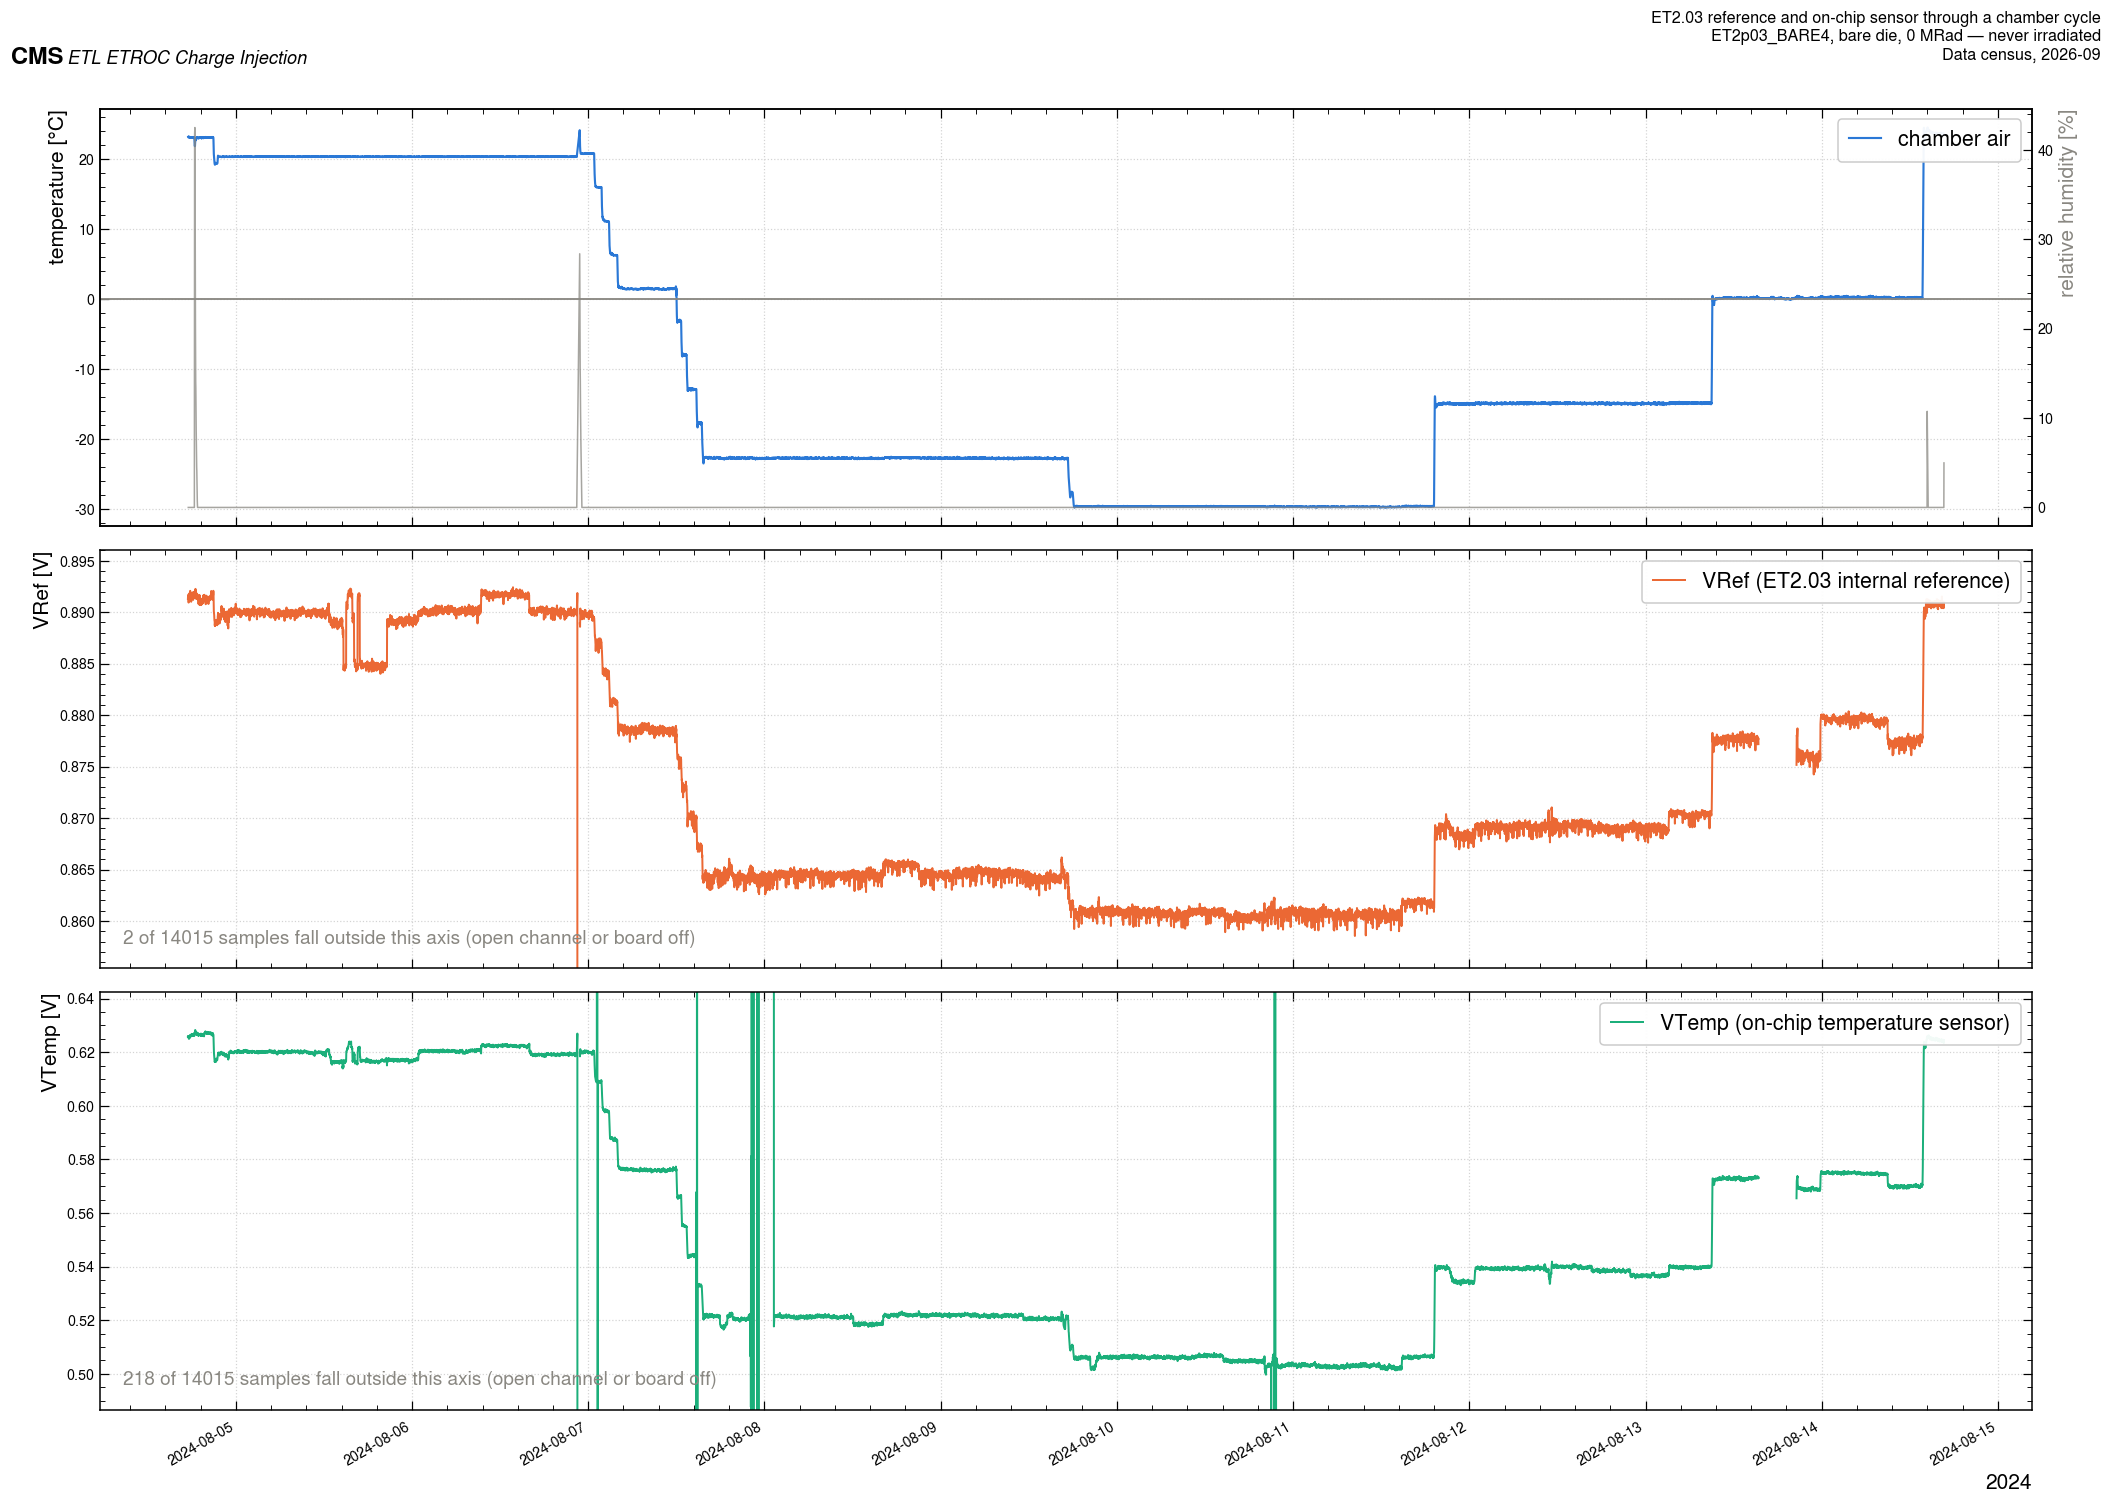

In [24]:
# 7.6b  FIGURE 8 — the whole campaign: chamber, VRef and VTemp on one time axis.
vr = VOL[VOL.instrument == "VRef"].sort_values("timestamp")
vt = VOL[VOL.instrument == "VTemp"].sort_values("timestamp")
fig, axes = plt.subplots(3, 1, figsize=(19, 13), sharex=True)
axes[0].plot(CHM.timestamp, CHM.temperature_C, color=Q.C_BLUE, lw=1.4, label="chamber air")
axes[0].set_ylabel("temperature [°C]")
axes[0].axhline(0, color=Q.GREY, lw=1.2)
ax0b = axes[0].twinx()
ax0b.plot(CHM.timestamp, CHM.humidity_pct, color=Q.GREY, lw=1.0, alpha=0.75)
ax0b.set_ylabel("relative humidity [%]", color=Q.GREY)
ax0b.grid(False)
axes[0].legend(loc="upper right", fontsize=14)
for ax, s, col, lab, win in [(axes[1], vr, Q.C_ORANGE, "VRef (ET2.03 internal reference)",
                              Q.CCTS_VREF_WINDOW),
                             (axes[2], vt, Q.C_AQUA, "VTemp (on-chip temperature sensor)",
                              Q.CCTS_VTEMP_WINDOW)]:
    d = s.copy()
    d.loc[d.timestamp.diff() > pd.Timedelta(minutes=10), "voltage_V"] = np.nan
    ax.plot(d.timestamp, d.voltage_V, color=col, lw=1.3, label=lab)
    inw = s.voltage_V[s.voltage_V.between(*win)]
    lo_q, hi_q = inw.quantile([0.002, 0.998])
    pad = 0.12 * (hi_q - lo_q)
    ax.set_ylim(lo_q - pad, hi_q + pad)
    n_out = int((~s.voltage_V.between(lo_q - pad, hi_q + pad)).sum())
    ax.set_ylabel("%s [V]" % lab.split(" ")[0])
    ax.legend(loc="upper right", fontsize=14)
    ax.text(0.012, 0.06, "%d of %d samples fall outside this axis (open channel or board off)"
            % (n_out, len(s)), transform=ax.transAxes, fontsize=12.5, color=Q.GREY)
axes[2].set_xlabel("2024")
fig.autofmt_xdate()
fig.tight_layout()
header(fig, "ET2.03 reference and on-chip sensor through a chamber cycle",
       tag="ET2p03_BARE4, bare die, 0 MRad — never irradiated", scale=0.66, y=1.012)
Q.save_fig(fig, "census_fig8_ccts_monitoring")
plt.show()

Both channels track the chamber. The next cell turns that into a number, and the number is what
section 8 has been missing.

**The uncertainty needs care.** The samples are one per minute over ten days and the chamber moves
slowly, so consecutive samples are anything but independent: an ordinary least-squares standard
error over 14 000 correlated points would be absurdly small. The slope quoted below is therefore
fitted to **temperature-binned medians** with the weight of each bin taken from its own scatter,
and the per-sample fit is printed beside it only to show that the two agree on the value.

The binned fit's χ²/ndf comes out in the hundreds, and that is information rather than a problem:
it says a **straight line is an approximation** to a response measured over 54 °C, not that the
points scatter. The quoted uncertainty is therefore the fit error inflated by √(χ²/ndf), which is
how far a linear coefficient can honestly be pushed on a curve this well measured.

In [25]:
# 7.6c  DERIVED: VRef and VTemp against chamber temperature, binned and fitted.
V2 = VOL.copy()
V2["m"] = V2.timestamp.dt.floor("min")
C2 = CHM.copy()
C2["m"] = C2.timestamp.dt.floor("min")
J = V2.merge(C2[["m", "temperature_C"]], on="m", how="inner")

FITS = {}
for inst, win in [("VRef", Q.CCTS_VREF_WINDOW), ("VTemp", Q.CCTS_VTEMP_WINDOW)]:
    g = J[(J.instrument == inst) & (J.voltage_V.between(*win))].copy()
    g["Tbin"] = (g.temperature_C / 2.0).round() * 2.0
    b = g.groupby("Tbin").voltage_V.agg(["median", "std", "size"]).reset_index()
    b = b[b["size"] >= 20]
    sy = (b["std"] / np.sqrt(b["size"])).clip(lower=1e-5)
    s, i, se, ie, chi2, res = Q.wls(b.Tbin.values, b["median"].values, sy.values)
    ols = np.polyfit(g.temperature_C, g.voltage_V, 1)[0]
    ndf = max(len(b) - 2, 1)
    # chi2/ndf >> 1 here, and it is not scatter: a straight line is an approximation to a curve
    # over 54 degrees. The quoted uncertainty is therefore the fit error inflated by
    # sqrt(chi2/ndf), the usual treatment of an underfitting model -- it is a statement about how
    # well a LINE describes the response, not about how well the slope is measured.
    scale = np.sqrt(max(chi2 / ndf, 1.0))
    FITS[inst] = dict(slope_mV_per_C=s * 1e3, err_mV_per_C=se * 1e3 * scale,
                      err_raw_mV_per_C=se * 1e3, intercept_V=i, chi2_ndf=chi2 / ndf,
                      nbin=len(b), n=len(g), ols_mV_per_C=ols * 1e3, bins=b, sy=sy)
    print("%-6s  %d samples in %d temperature bins" % (inst, len(g), len(b)))
    print("        binned weighted fit : %+.4f ± %.4f mV/°C (quoted), intercept %.4f V at 0 °C"
          % (s * 1e3, se * 1e3 * scale, i))
    print("        χ²/ndf %.0f over %d bins, so the ± above is the fit error inflated by √(χ²/ndf)"
          % (chi2 / ndf, len(b)))
    print("        = %.4f × %.1f: a line is an approximation to this response, not a fit to noise."
          % (se * 1e3, scale))
    print("        per-sample OLS slope: %+.4f mV/°C  (value agrees; its error would not be honest)"
          % (ols * 1e3))
vref0 = FITS["VRef"]["intercept_V"]
print("\nDERIVED: over the %.0f °C the chamber covered, the ET2.03 internal reference moves"
      % (CHM.temperature_C.max() - CHM.temperature_C.min()))
print("  %.1f mV on a %.3f V reference, i.e. %.2f %% — and %+.3f %% per °C."
      % (abs(FITS["VRef"]["slope_mV_per_C"]) * (CHM.temperature_C.max() - CHM.temperature_C.min()),
         vref0,
         100 * abs(FITS["VRef"]["slope_mV_per_C"]) * 1e-3
         * (CHM.temperature_C.max() - CHM.temperature_C.min()) / vref0,
         100 * FITS["VRef"]["slope_mV_per_C"] * 1e-3 / vref0))

VRef    14005 samples in 17 temperature bins
        binned weighted fit : +0.5728 ± 0.0066 mV/°C (quoted), intercept 0.8776 V at 0 °C
        χ²/ndf 417 over 17 bins, so the ± above is the fit error inflated by √(χ²/ndf)
        = 0.0003 × 20.4: a line is an approximation to this response, not a fit to noise.
        per-sample OLS slope: +0.5791 mV/°C  (value agrees; its error would not be honest)
VTemp   13794 samples in 17 temperature bins
        binned weighted fit : +2.2701 ± 0.0203 mV/°C (quoted), intercept 0.5728 V at 0 °C
        χ²/ndf 643 over 17 bins, so the ± above is the fit error inflated by √(χ²/ndf)
        = 0.0008 × 25.4: a line is an approximation to this response, not a fit to noise.
        per-sample OLS slope: +2.2864 mV/°C  (value agrees; its error would not be honest)

DERIVED: over the 54 °C the chamber covered, the ET2.03 internal reference moves
  31.1 mV on a 0.878 V reference, i.e. 3.55 % — and +0.065 % per °C.


In [26]:
# 7.6c-bis  Export the two calibration slopes so that notebook 04 can quote them without
# recomputing anything (its contract is that it reads only `outputs/`).
VFIT = pd.DataFrame([
    dict(instrument=k, slope_mV_per_C=v["slope_mV_per_C"], err_mV_per_C=v["err_mV_per_C"],
         err_raw_mV_per_C=v["err_raw_mV_per_C"], intercept_V=v["intercept_V"],
         chi2_ndf=v["chi2_ndf"], n_bins=v["nbin"], n_samples=v["n"],
         ols_mV_per_C=v["ols_mV_per_C"], chip="ET2p03_BARE4", dose_MRad=0.0)
    for k, v in FITS.items()])
VFIT.to_csv(Q.OUTDIR / "census_ccts_vref_vtemp_fit.csv", index=False)
print("wrote outputs/census_ccts_vref_vtemp_fit.csv, the ET2p03_BARE4 calibration slopes:")
print(VFIT[["instrument", "chip", "slope_mV_per_C", "err_mV_per_C", "intercept_V",
            "chi2_ndf", "n_samples"]].round(4).to_string(index=False))

wrote outputs/census_ccts_vref_vtemp_fit.csv, the ET2p03_BARE4 calibration slopes:
instrument         chip  slope_mV_per_C  err_mV_per_C  intercept_V  chi2_ndf  n_samples
      VRef ET2p03_BARE4          0.5728        0.0066       0.8776  416.9761      14005
     VTemp ET2p03_BARE4          2.2701        0.0203       0.5728  643.2382      13794


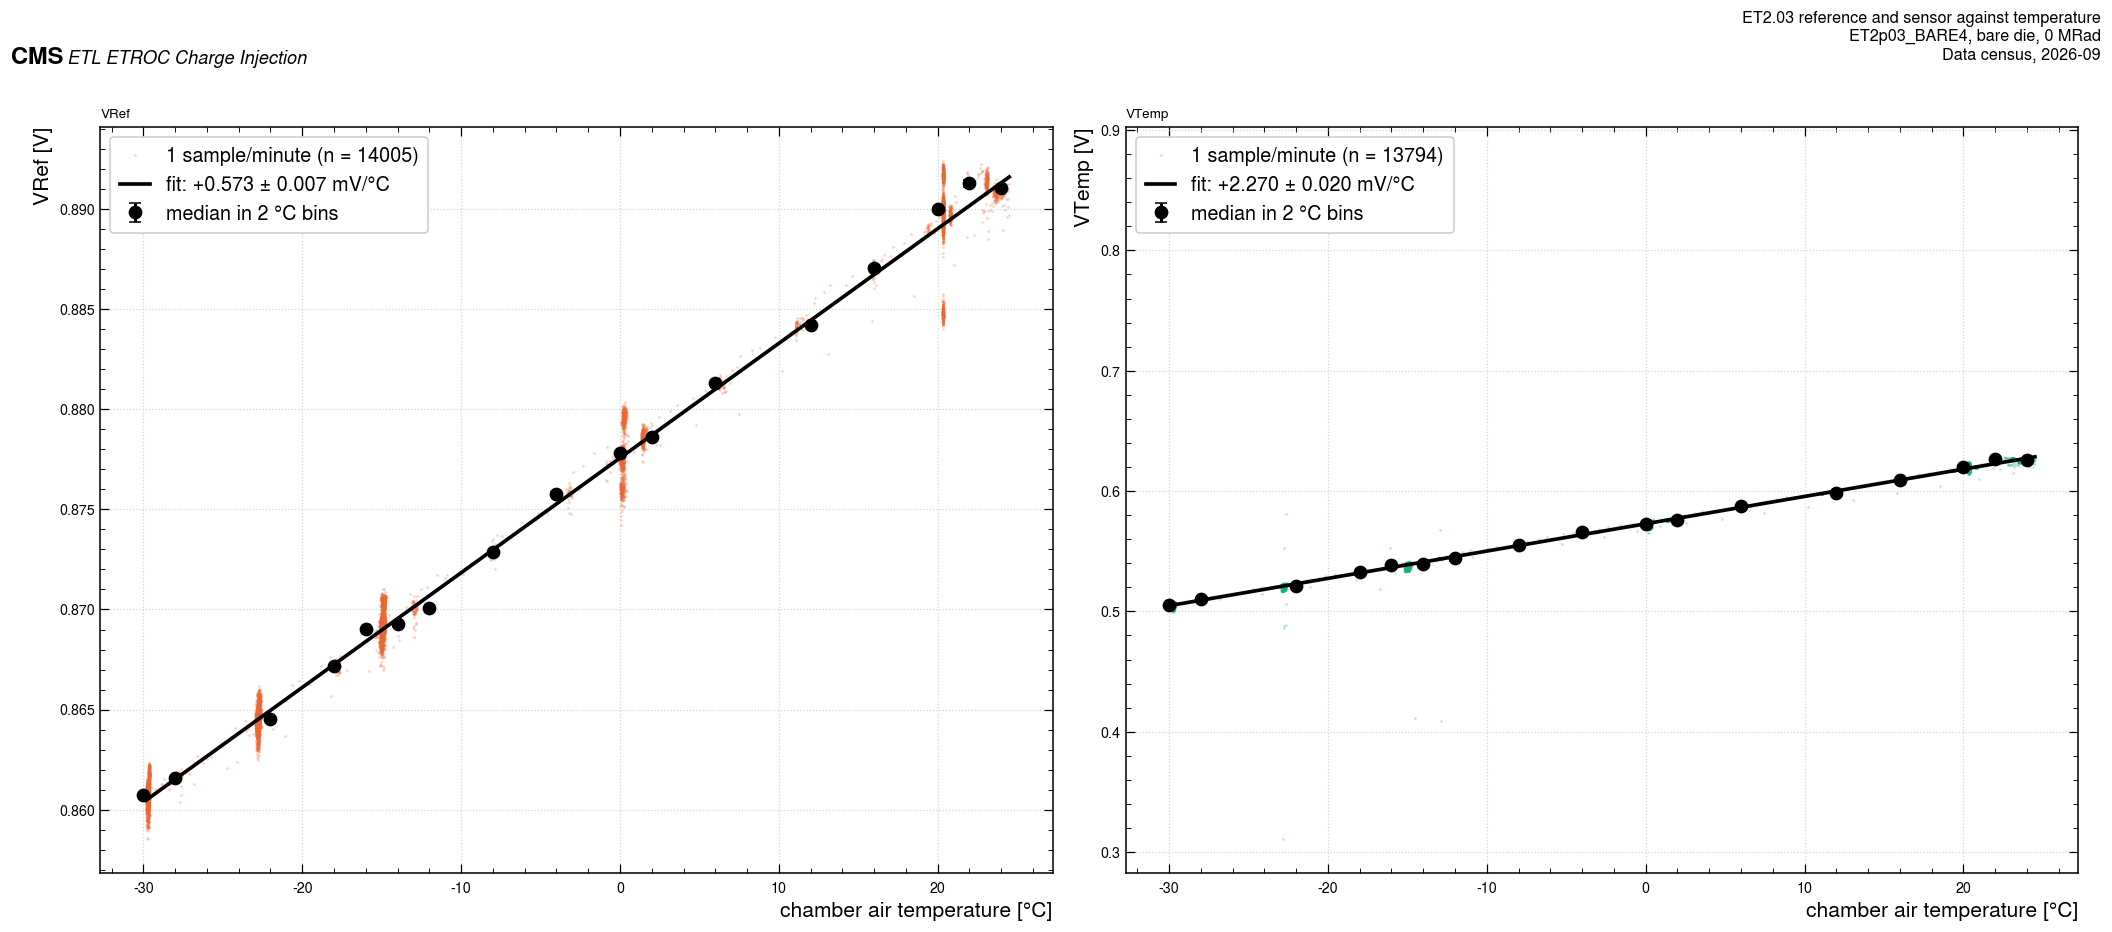

In [27]:
# 7.6d  FIGURE 9 — the two calibrations.
fig, axes = plt.subplots(1, 2, figsize=(19, 7.8))
for ax, inst, col, ylab in [(axes[0], "VRef", Q.C_ORANGE, "VRef [V]"),
                            (axes[1], "VTemp", Q.C_AQUA, "VTemp [V]")]:
    win = Q.CCTS_VREF_WINDOW if inst == "VRef" else Q.CCTS_VTEMP_WINDOW
    g = J[(J.instrument == inst) & (J.voltage_V.between(*win))]
    f = FITS[inst]
    ax.plot(g.temperature_C, g.voltage_V, ".", ms=2.0, color=col, alpha=0.18,
            label="1 sample/minute (n = %d)" % len(g))
    ax.errorbar(f["bins"].Tbin, f["bins"]["median"], yerr=f["sy"], fmt="o", ms=8, lw=2,
                capsize=4, color=INK, label="median in 2 °C bins")
    xs = np.linspace(g.temperature_C.min(), g.temperature_C.max(), 50)
    ax.plot(xs, f["intercept_V"] + f["slope_mV_per_C"] * 1e-3 * xs, "-", lw=2.4, color=INK,
            label="fit: %+.3f ± %.3f mV/°C" % (f["slope_mV_per_C"], f["err_mV_per_C"]))
    ax.set_xlabel("chamber air temperature [°C]")
    ax.set_ylabel(ylab)
    ax.set_title(inst, loc="left")
    ax.legend(fontsize=13, loc="upper left")
fig.tight_layout()
header(fig, "ET2.03 reference and sensor against temperature",
       tag="ET2p03_BARE4, bare die, 0 MRad", scale=0.66, y=1.02)
Q.save_fig(fig, "census_fig9_ccts_vref_vs_temp")
plt.show()

**What these two numbers are, and what they are not.**

`VTemp` is the *point* of the on-chip sensor, so its slope is a **calibration**: the sensor
responds to chamber air at the millivolts-per-degree printed above, over a 54 °C span, with a
correlation that the figure makes obvious. It is measured against **chamber air**, not against
the die, so it inherits whatever offset the die-to-air gradient carries; it is a scale, not an
absolute thermometer.

`VRef` is the *problem*. The ET2.03 internal reference is not a fixed voltage: it drifts by the
printed slope, a few tenths of a per cent per degree. That is small, and it is not nothing —
anything that scales with the reference inherits it. The cell below asks whether the campaign's
own baseline shift can be blamed on it, and the answer is no.

In [28]:
# 7.6e  DERIVED: the baselines of this campaign against temperature, at the nominal rails.
CBL2 = CBL.sort_values("timestamp").reset_index(drop=True)
CBL2["map_id"] = CBL2.index // 256
MAPS = (CBL2.groupby("map_id")
        .agg(t=("timestamp", "median"), note=("save_notes", "first"), T=("note_temp_C", "first"),
             va=("note_va_nominal_V", "first"), vd=("note_vd_nominal_V", "first"),
             BL=("baseline", "mean"), BL_sd=("baseline", "std"),
             NW=("noise_width", "mean"), NW_sd=("noise_width", "std"), n=("baseline", "size"))
        .reset_index())
assert set(MAPS.n) == {256}, MAPS.n.unique()
NOM = MAPS[(MAPS.va == 1.2) & (MAPS.vd == 1.2)]
print("140 maps, %d of them at the nominal rails (A 1.2 V, D 1.2 V), over %d temperatures.\n"
      % (len(NOM), NOM["T"].nunique()))
tb = NOM.groupby("T").agg(maps=("BL", "size"), BL=("BL", "mean"), BL_rms=("BL", "std"),
                          NW=("NW", "mean")).round(2)
print(tb.to_string())
sb, ib, seb, ieb, chib, _ = Q.wls(NOM["T"].values, NOM.BL.values,
                                  np.maximum(NOM.BL_sd.values / 16.0, 0.1))
seb *= np.sqrt(max(chib / max(len(NOM) - 2, 1), 1.0))
print("\nDERIVED: array-mean baseline against the note temperature, %d maps:" % len(NOM))
print("  %.3f ± %.3f DAC per °C  (BL falls as the chip warms), intercept %.1f DAC at 0 °C"
      % (sb, seb, ib))
print("  ± inflated by √(χ²/ndf) = %.1f, for the same reason as cell 7.6c."
      % np.sqrt(max(chib / max(len(NOM) - 2, 1), 1.0)))
frac = FITS["VRef"]["slope_mV_per_C"] * 1e-3 / vref0
print("\n  The internal reference drifts %+.4f %%/°C (cell 7.6c). IF the threshold DAC's full scale"
      % (100 * frac))
print("  tracked that reference -- which nothing in this census establishes -- a %.0f-DAC baseline"
      % NOM.BL.mean())
print("  would move %.2f DAC/°C from the reference alone, against the %.2f DAC/°C measured."
      % (abs(frac) * NOM.BL.mean(), abs(sb)))
print("  So at most ~%.0f %% of the baseline's temperature dependence could be the reference;"
      % (100 * abs(frac) * NOM.BL.mean() / abs(sb)))
print("  the rest is the front end itself.")

140 maps, 33 of them at the nominal rails (A 1.2 V, D 1.2 V), over 18 temperatures.

       maps      BL  BL_rms    NW
T                                
-29.7     4  875.75    1.65  4.11
-22.8     3  845.23    1.42  4.07
-22.7     1  845.64     NaN  4.02
-17.7     1  822.13     NaN  3.96
-15.0     3  809.81    0.82  3.99
-13.0     1  801.25     NaN  4.00
-8.0      1  777.97     NaN  3.96
-3.1      1  756.03     NaN  3.86
 0.0      3  741.49    3.25  3.87
 1.5      1  735.46     NaN  3.89
 6.2      2  714.32    0.01  3.83
 11.1     1  692.90     NaN  3.78
 16.0     2  670.56    0.06  3.83
 20.3     3  648.79    0.12  3.78
 20.5     1  650.64     NaN  3.79
 20.7     1  649.21     NaN  3.71
 21.2     1  647.48     NaN  3.75
 23.0     3  636.56    0.40  3.73

DERIVED: array-mean baseline against the note temperature, 33 maps:
  -4.526 ± 0.013 DAC per °C  (BL falls as the chip warms), intercept 741.9 DAC at 0 °C
  ± inflated by √(χ²/ndf) = 1.8, for the same reason as cell 7.6c.

  The inter

  Analog   12 temperature bins, 12 kept with at least 40 samples (dropped: none)
  Digital  11 temperature bins, 11 kept with at least 40 samples (dropped: none)


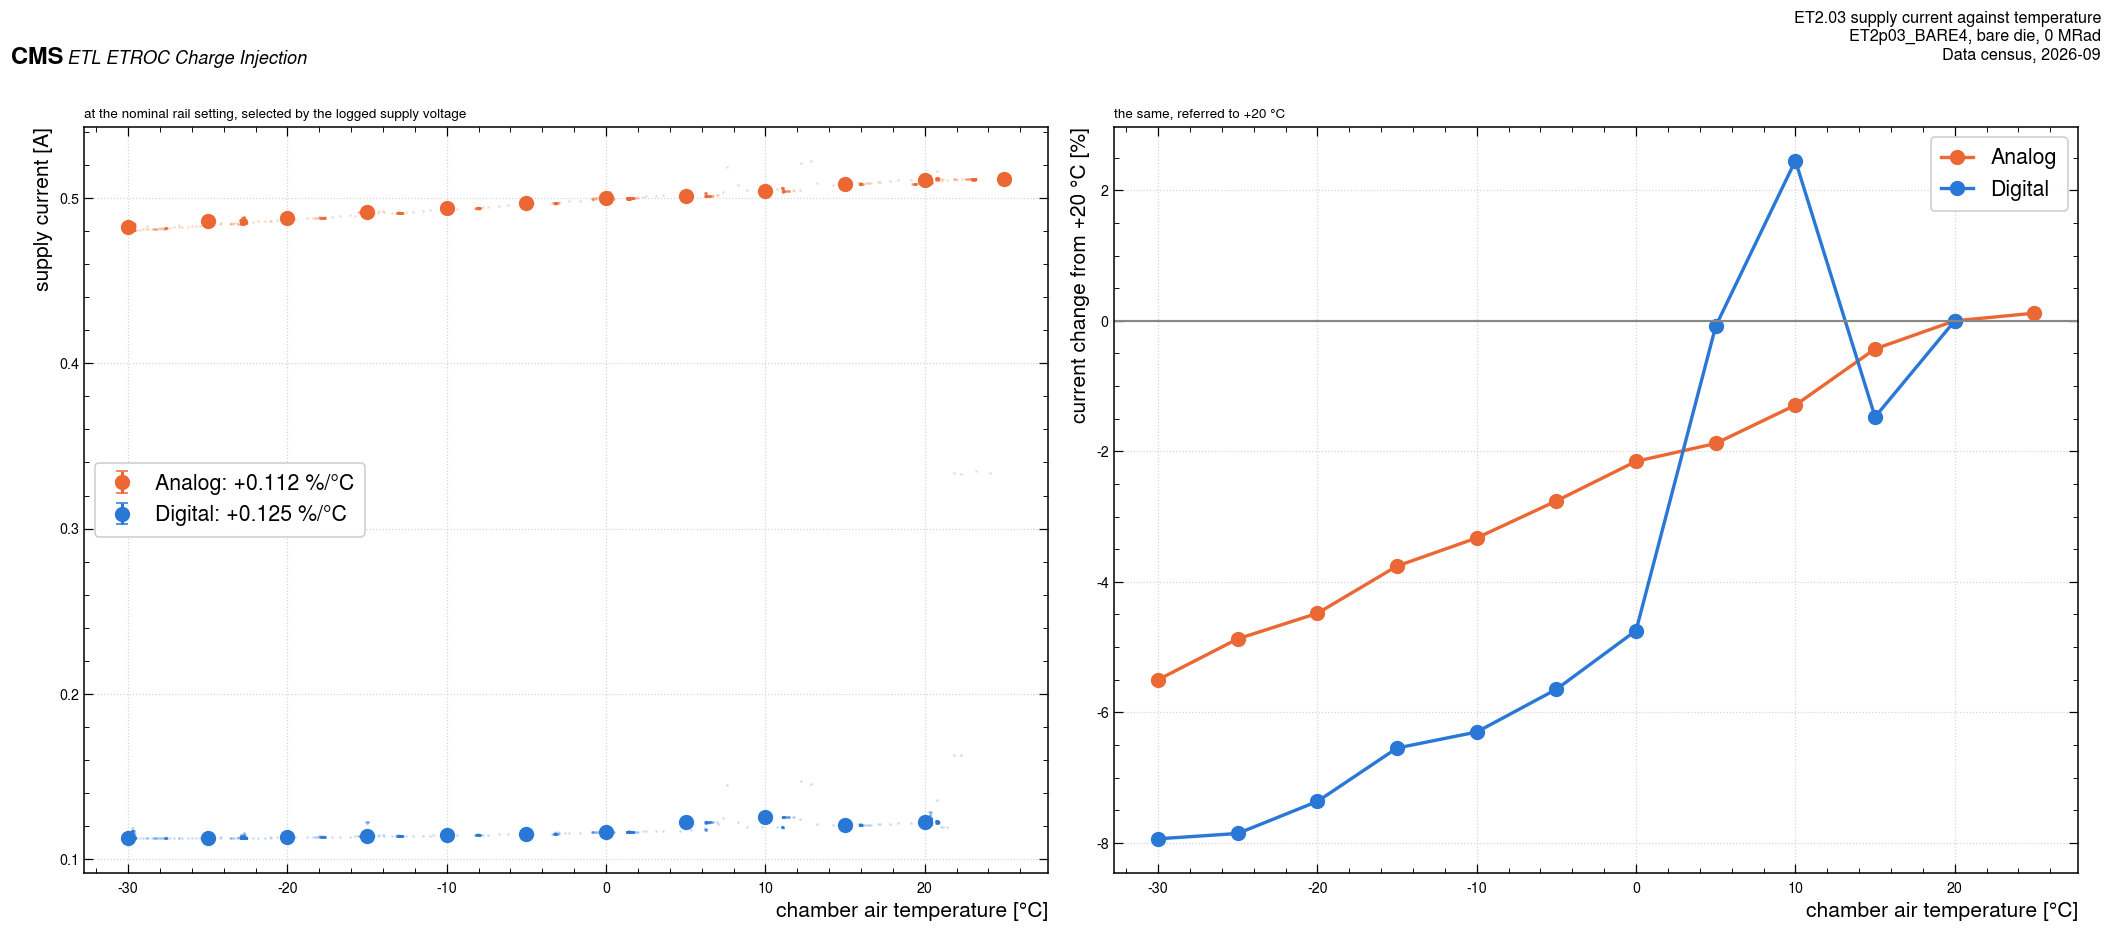

DERIVED, from the binned fits above (± inflated by √(χ²/ndf), as in cell 7.6c):
  Analog   +0.00057 ± 0.00001 A/°C = +0.112 %/°C of the +20 °C value (n = 8483, χ²/ndf 119)
  Digital  +0.00015 ± 0.00001 A/°C = +0.125 %/°C of the +20 °C value (n = 8879, χ²/ndf 1045)
  The sign is the one that matters: on this die, at a fixed supply setting, **cooling
  LOWERS the analog current**.


In [29]:
# 7.6f  FIGURE 10 — supply rails against temperature, at a rail setting selected by measurement.
CLV2 = CLV.copy()
CLV2["m"] = CLV2.timestamp.dt.floor("min")
LJ = CLV2[CLV2.instrument == "Power1"].merge(C2[["m", "temperature_C"]], on="m", how="inner")
NOMV = {"Analog": 1.3773, "Digital": 1.2289}     # the supply reading at the nominal rail setting
fig, (ax, ax2) = plt.subplots(1, 2, figsize=(19, 7.8))
TC = {}
for rail, col in [("Analog", Q.C_ORANGE), ("Digital", Q.C_BLUE)]:
    g = LJ[(LJ.rail == rail) & ((LJ.V - NOMV[rail]).abs() < 0.005)].copy()
    g["Tbin"] = (g.temperature_C / 5.0).round() * 5.0
    b_all = g.groupby("Tbin").I_A.agg(["median", "std", "size"]).reset_index()
    b = b_all[b_all["size"] >= 40]
    print("  %-8s %d temperature bins, %d kept with at least 40 samples (dropped: %s)"
          % (rail, len(b_all), len(b),
             ", ".join("%+.0f °C (n=%d)" % (r.Tbin, r["size"])
                       for _, r in b_all[b_all["size"] < 40].iterrows()) or "none"))
    sy = (b["std"] / np.sqrt(b["size"])).clip(lower=1e-6)
    s, i, se, ie, chi2, _ = Q.wls(b.Tbin.values, b["median"].values, sy.values)
    ref = float(b[b.Tbin == 20.0]["median"].iloc[0])
    scale = np.sqrt(max(chi2 / max(len(b) - 2, 1), 1.0))
    TC[rail] = dict(slope=s, err=se * scale, ref=ref, pct=100 * s / ref, n=len(g),
                    chi2_ndf=chi2 / max(len(b) - 2, 1))
    ax.plot(g.temperature_C, g.I_A, ".", ms=2, color=col, alpha=0.15)
    ax.errorbar(b.Tbin, b["median"], yerr=sy, fmt="o", ms=9, lw=2, capsize=4, color=col,
                label="%s: %+.3f %%/°C" % (rail, 100 * s / ref))
    ax2.plot(b.Tbin, 100 * (b["median"] / ref - 1), "o-", ms=9, lw=2.2, color=col, label=rail)
ax.set_xlabel("chamber air temperature [°C]")
ax.set_ylabel("supply current [A]")
ax.set_title("at the nominal rail setting, selected by the logged supply voltage", loc="left")
ax.legend(fontsize=14)
ax2.axhline(0, color=Q.GREY, lw=1.4)
ax2.set_xlabel("chamber air temperature [°C]")
ax2.set_ylabel("current change from +20 °C [%]")
ax2.set_title("the same, referred to +20 °C", loc="left")
ax2.legend(fontsize=14)
fig.tight_layout()
header(fig, "ET2.03 supply current against temperature",
       tag="ET2p03_BARE4, bare die, 0 MRad", scale=0.66, y=1.02)
Q.save_fig(fig, "census_fig10_ccts_lv_vs_temp")
plt.show()
print("DERIVED, from the binned fits above (± inflated by √(χ²/ndf), as in cell 7.6c):")
for rail in ["Analog", "Digital"]:
    d = TC[rail]
    print("  %-8s %+.5f ± %.5f A/°C = %+.3f %%/°C of the +20 °C value (n = %d, χ²/ndf %.0f)"
          % (rail, d["slope"], d["err"], d["pct"], d["n"], d["chi2_ndf"]))
print("  The sign is the one that matters: on this die, at a fixed supply setting, **cooling")
print("  LOWERS the analog current**.")

### The bearing this has on section 7.1, and it is not comfortable

Section 7.1 found a **+36.6 %** step in the analog current of the ET2.01 TID campaign that
coincided with a cooldown from +12 to −25 °C, and stopped short of calling it a temperature
effect because the supply voltage moved at the same time. The cell above is the only direct
measurement of a temperature coefficient of analog current anywhere in this census, and it says
that cooling an ETROC2 die at a fixed supply setting **reduces** the analog current, by about a
tenth of a per cent per degree — a few per cent over the whole 54 °C span, and of the **opposite
sign** to the ET2.01 step.

It does not transfer: different revision, different die, different board, different supply
setting, and the ET2.01 supply moved as well. What it does do is remove the easy story. The
ET2.01 step is not explained by dose (section 7.1 proves that from the dose tags) and is not
explained by cooling either, because on the one chip where cooling was measured against current
it acts the other way. **It remains unexplained**, and this notebook says so rather than picking
whichever of the three simultaneous changes reads best.

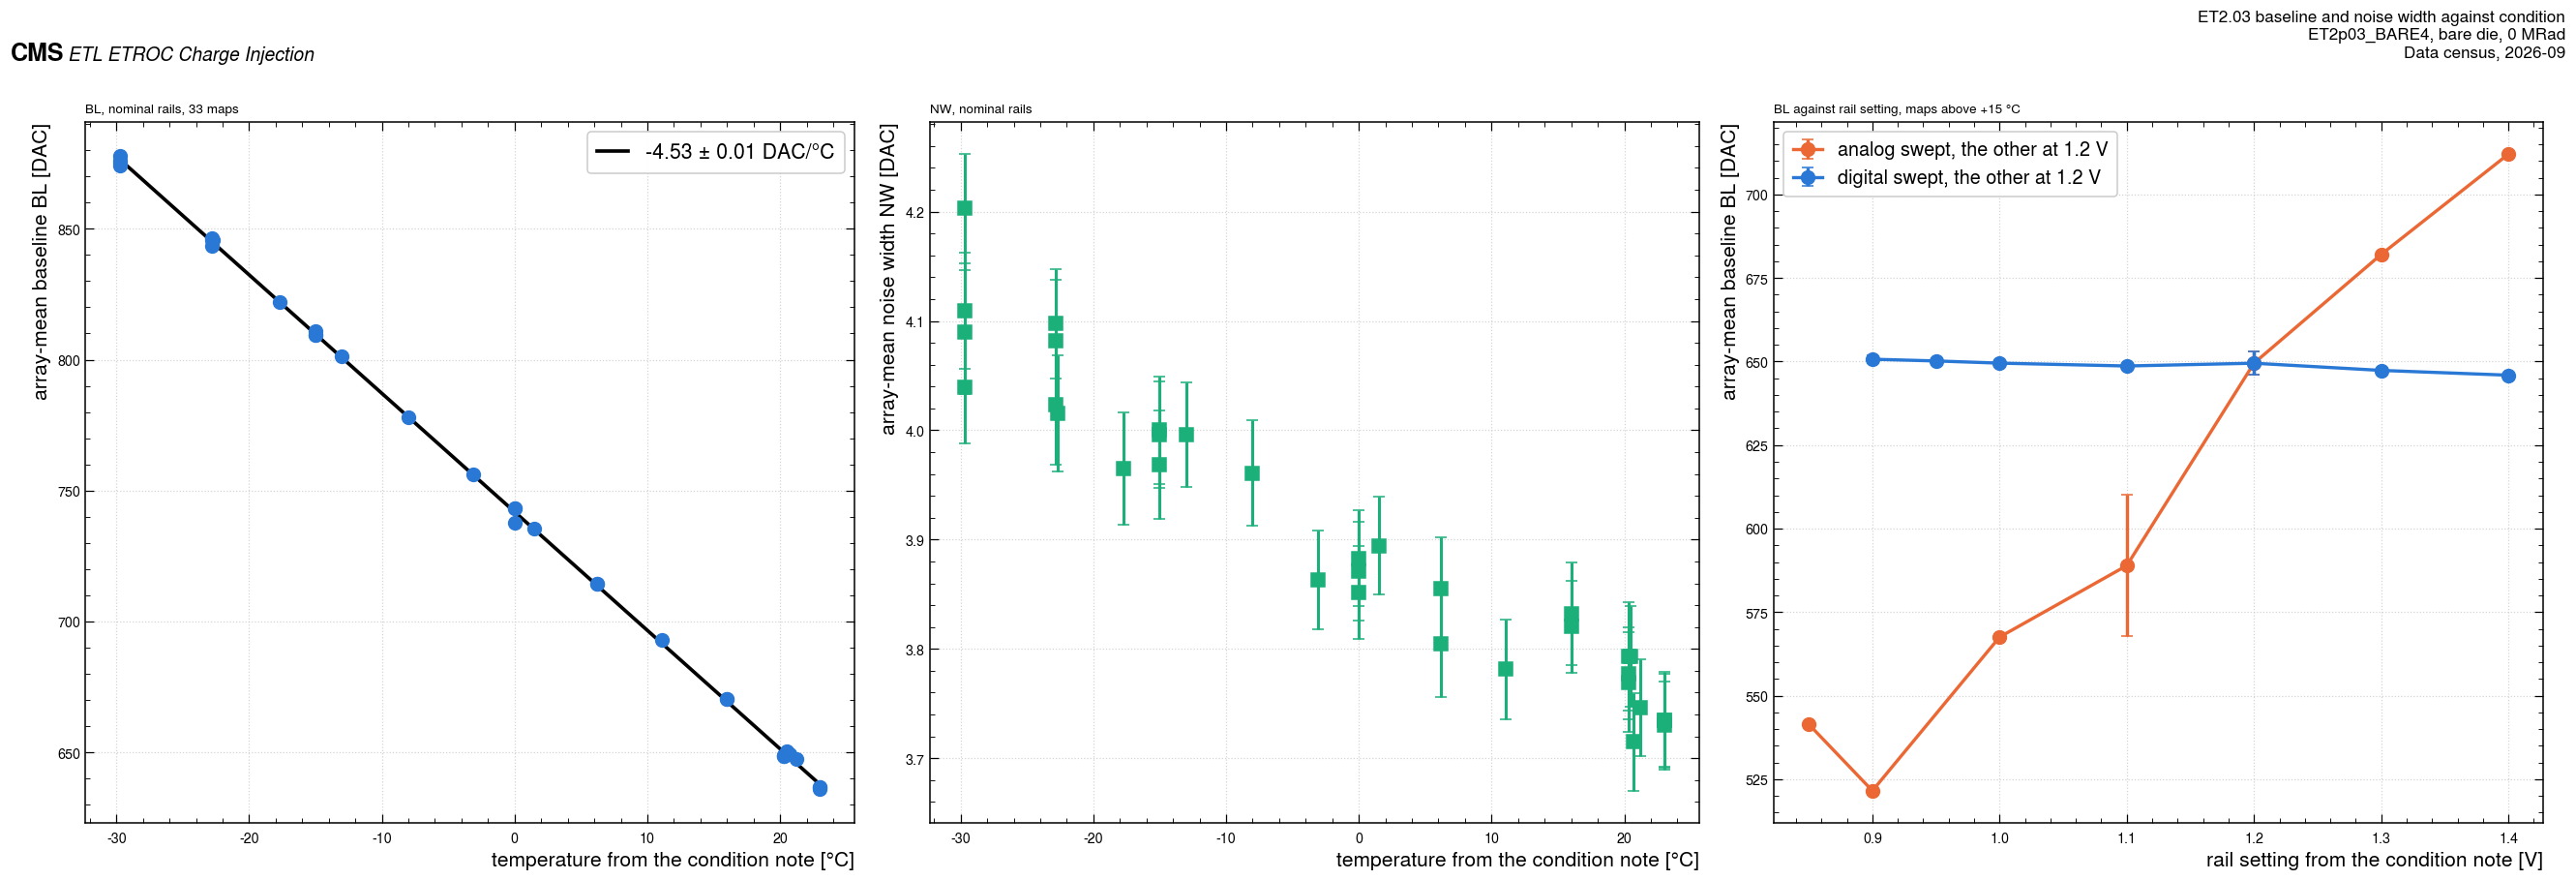

In [30]:
# 7.6g  FIGURE 11 — baseline and noise width against temperature and against rail setting.
fig, axes = plt.subplots(1, 3, figsize=(24, 7.6))
axes[0].errorbar(NOM["T"], NOM.BL, yerr=NOM.BL_sd / 16.0, fmt="o", ms=9, lw=2, capsize=4,
                 color=Q.C_BLUE)
xs = np.linspace(NOM["T"].min(), NOM["T"].max(), 20)
axes[0].plot(xs, ib + sb * xs, "-", lw=2.4, color=INK,
             label="%.2f ± %.2f DAC/°C" % (sb, seb))
axes[0].set_xlabel("temperature from the condition note [°C]")
axes[0].set_ylabel("array-mean baseline BL [DAC]")
axes[0].set_title("BL, nominal rails, %d maps" % len(NOM), loc="left")
axes[0].legend(fontsize=14)
axes[1].errorbar(NOM["T"], NOM.NW, yerr=NOM.NW_sd / 16.0, fmt="s", ms=9, lw=2, capsize=4,
                 color=Q.C_AQUA)
axes[1].set_xlabel("temperature from the condition note [°C]")
axes[1].set_ylabel("array-mean noise width NW [DAC]")
axes[1].set_title("NW, nominal rails", loc="left")
WARM = MAPS[(MAPS["T"] > 15)]
for ax, xcol, other, lab, col in [(axes[2], "va", "vd", "analog", Q.C_ORANGE),
                                  (axes[2], "vd", "va", "digital", Q.C_BLUE)]:
    g = WARM[WARM[other] == 1.2].groupby(xcol).BL.agg(["mean", "std", "size"]).reset_index()
    axes[2].errorbar(g[xcol], g["mean"], yerr=(g["std"] / np.sqrt(g["size"])).fillna(0.0),
                     fmt="o-", ms=9, lw=2.2, capsize=4, color=col,
                     label="%s swept, the other at 1.2 V" % lab)
axes[2].set_xlabel("rail setting from the condition note [V]")
axes[2].set_ylabel("array-mean baseline BL [DAC]")
axes[2].set_title("BL against rail setting, maps above +15 °C", loc="left")
axes[2].legend(fontsize=13)
fig.tight_layout()
header(fig, "ET2.03 baseline and noise width against condition",
       tag="ET2p03_BARE4, bare die, 0 MRad", scale=0.7, y=1.02)
Q.save_fig(fig, "census_fig11_ccts_blnw")
plt.show()

Three things to read off figure 11. The **baseline moves with temperature** at the slope fitted
in cell 7.6e, straight over 53 °C and far larger than anything the reference drift can explain.
The **noise width moves too**, but by about a tenth of its value across the whole span, which is
the difference between a threshold that must be re-found after a temperature change and a noise
figure that need not be. And the baseline **depends on the analog rail and not on the digital
one**: sweeping the analog setting from 0.85 to 1.40 V moves the array-mean baseline by more than
150 DAC, while sweeping the digital setting over the same range leaves it flat within a few DAC.
That is a useful independent statement of the same rail sensitivity the dose campaign's own
voltage scans were taken to probe.

In [31]:
# 7.6h  The rail figures in the condition note are not the supply readings, and the offset between
#       them is constant. This is the only measured version of the number notebook 03 assumes.
for rail, notecol, col in [("Analog", "va", "V_Analog"), ("Digital", "vd", "V_Digital")]:
    r = CLV[(CLV.instrument == "Power1") & (CLV.rail == rail)][["timestamp", "V"]] \
        .rename(columns={"V": col}).sort_values("timestamp")
    MAPS = pd.merge_asof(MAPS.sort_values("t"), r, left_on="t", right_on="timestamp",
                         direction="nearest", tolerance=pd.Timedelta("2min")) \
        .drop(columns=["timestamp"])
print("DERIVED: for every map, the supply terminal reading nearest in time (within 2 minutes),")
print("grouped by the rail figure written in that map's condition note.\n")
for rail, notecol, col in [("Analog", "va", "V_Analog"), ("Digital", "vd", "V_Digital")]:
    g = MAPS.groupby(notecol)[col].agg(["size", "median"]).reset_index()
    g["offset_V"] = (g["median"] - g[notecol]).round(4)
    g = g.rename(columns={notecol: "note [V]", "size": "maps", "median": "supply [V]"})
    print(rail)
    print(g.round(4).to_string(index=False))
    print("  offset over the %d settings: %.4f to %.4f V, spread %.4f V\n"
          % (len(g), g.offset_V.min(), g.offset_V.max(), g.offset_V.max() - g.offset_V.min()))

DERIVED: for every map, the supply terminal reading nearest in time (within 2 minutes),
grouped by the rail figure written in that map's condition note.

Analog
 note [V]  maps  supply [V]  offset_V
     0.85    20      1.0273    0.1773
     0.90     4      1.0767    0.1767
     1.00    18      1.1769    0.1769
     1.10     5      1.2779    0.1779
     1.20    66      1.3773    0.1773
     1.30     5      1.4765    0.1765
     1.40    22      1.5764    0.1764
  offset over the 7 settings: 0.1764 to 0.1779 V, spread 0.0015 V

Digital
 note [V]  maps  supply [V]  offset_V
     0.90     2      0.9338    0.0338
     0.95     5      0.9810    0.0310
     1.00    24      1.0260    0.0260
     1.10     4      1.1271    0.0271
     1.20    80      1.2289    0.0289
     1.30     8      1.3272    0.0272
     1.40    17      1.4263    0.0263
  offset over the 7 settings: 0.0260 to 0.0338 V, spread 0.0078 V



Across seven analog and seven digital settings spanning 0.85 to 1.40 V, the supply terminal reads
a **constant offset** above the figure written in the note — the cell prints both offsets and
shows the spread over the settings is a couple of millivolts. Whichever of the two numbers is the
voltage at the chip, the relationship between them on this board is a fixed offset and not a
scale factor.

That is the same *form* as the assumption notebook 03 has to make for the dose campaign, where
the only evidence is one logbook line (`Nominal Analog 1.2V = 1.4V on power supply`, implying
0.20 V and 0.05 V). The offsets measured here are not those values — this is a different board,
different cables and a different current — so this **does not correct** notebook 03's numbers.
It corroborates the shape of its approximation and gives the first measured example of the
quantity, and both of those are worth having written down.

### 7.7 The ET2.03 dose campaign's monitoring logs were written — and, since 2026-09-04, found

Section 7.3 says the ET2.03 August-2024 dose campaign's data tree contains no condition record
beyond its directory names. That is true of the tree, and it turns out to be the wrong conclusion
about the campaign.

On the bench PC there is an analysis notebook, `ETROC-Analysis/reading_history/cern_TID.ipynb`,
last modified 2025-06-02 and carrying no outputs. It opens **five** databases by name, all in one
folder, `ETROC-History/CERN_Aug_2024_TID_history/`:

| file it opens | what it reads from it |
|---|---|
| `BaselineHistory.sqlite` | baselines against time for `ET2p03_BARE9` (and, commented out, `BARE7`), 16 pixels of columns 7 and 8 |
| `ADCHistory.sqlite` | `channel == 7`, plotted as **VTemp** with a 0.52–0.575 V axis |
| `NEW_PowerHistory_v2.sqlite` | `Instrument == 'Power'`, the **Analog and Digital rail V and I** |
| `WS_PowerHistory_v2.sqlite` | `Instrument == 'WS Power'`, the **waveform-sampler rail** |
| `vol_monitoring.sqlite` | **VRef**, plotted over the irradiation with a 0.80–0.91 V axis |

A notebook that reads five files by name, selects specific channels in them, and sets axis limits
that match the physical values is written **against data that existed**. It also carries the
campaign's irradiation timeline written out twice. **The folder itself was supplied by the
campaign's operator on 2026-09-04** (as `CERN_Aug_2024_TID.zip`, together with a second
climate-chamber set, `CERN_Aug_2024_CC_Spirale3.zip`) and both now live on LPC EOS under
`cern_Aug2024_TID/ETROC-History/` and `cern_Aug2024_CC/ETROC-History/`. Notebook 03 section 15
analyses the TID logs; the aux matrix rows above reflect what they contain.

In [32]:
TL = Q.load_tid_et2p03_timeline()
print("RAW, transcribed from the analysis notebook. Irradiation steps of the ET2.03 dose campaign:")
print()
print(TL.to_string(index=False))
steps = TL.pivot(index="step", columns="edge", values="timestamp")
steps["hours"] = (steps["stop"] - steps["start"]).dt.total_seconds() / 3600
print("\nDERIVED, step durations:")
for s, r in steps.iterrows():
    print("  step %s  %s -> %s  = %6.1f h" % (s, r["start"], r["stop"], r["hours"]))
print("\nSteps 1 and 2 bracket the 0 -> 200 -> 400 MRad points of census rows 6 and 7; the")
print("directory names of that campaign carry `200MRad` from 2024-08-07 and `400MRad` from")
print("2024-08-11, which is consistent with these markers and was recorded independently of them.")
print("\nOne disagreement inside the notebook is carried rather than resolved: its prose comment")
print("puts the end of step 3 at 01:30 on 2024-08-19, while a commented-out plotting array in the")
print("same notebook uses 02:30. Both are in the staged table's source column.")

# Step 3 dates the BARE7 0 MRad day, and independently of any directory tag.
s3 = steps.loc[3, "start"]
cc = Q.load_et2p03_chipconfig()
b7 = cc[cc.file.str.contains("BARE7_0MRad")].file.iloc[0]
t7 = pd.to_datetime(b7.split("_ET2p03")[0], format="%Y-%m-%dT%H-%M-%S.%f")
print("\nSTEP 3 DATES THE BARE7 0 MRad DAY, and does it independently of any directory tag.")
print("  step 3 irradiation starts        %s" % s3)
print("  BARE7 register dump of that day  %s   (%s)" % (t7, b7))
print("  the dump precedes the start of irradiation by %.0f minutes, on the same day"
      % ((s3 - t7).total_seconds() / 60))
print("  That day directory is `2024-08-14_Array_Test_Results`, the BARE7 0 MRad money plots that")
print("  notebook 03 sections 14 and 14.1 use, and the dump is that session's register read-back.")
print("  So the session CLOSED five minutes before the third irradiation step opened. Its `0MRad`")
print("  tag is a directory name; this timeline is a separate record, transcribed from the")
print("  campaign's own analysis notebook, and the two agree -- the BARE7 0 MRad money plot is")
print("  PRE-IRRADIATION. Nothing in notebook 03's BARE7 dose step rests on the directory tag")
print("  alone. (Both timestamps are the DAQ's own clock. The copied tree's directory mtimes run")
print("  02:04 -> 06:59 -> 10:15 -> 14:21 on 2024-08-14 for the three run directories and then")
print("  ChipConfig; that is a different clock offset, but the ORDER is the same and puts every")
print("  money-plot run of the day before the register dump.)")

RAW, transcribed from the analysis notebook. Irradiation steps of the ET2.03 dose campaign:

 step  edge           timestamp                                                                               source_in_notebook
    1 start 2024-08-04 23:48:00                                           cell 12 comment; plotted as lines[0] in cells 7 and 24
    1  stop 2024-08-07 02:46:00                                           cell 12 comment; plotted as lines[1] in cells 7 and 24
    2 start 2024-08-08 17:23:00                                           cell 12 comment; plotted as lines[2] in cells 7 and 24
    2  stop 2024-08-10 20:22:00                                           cell 12 comment; plotted as lines[3] in cells 7 and 24
    3 start 2024-08-14 21:27:00                             cell 12 comment; the commented lines array of cell 24 gives 21:27:30
    3  stop 2024-08-19 01:30:00 cell 12 comment; the commented lines array of cell 24 gives 02:30 -- DISAGREEMENT, both recorded
    

**Where the folder was looked for before it turned up** (all read-only, 2026-09-04): the whole
disk of `fermilab-etroc3`, the `etroclaptop3` backup on the X9 disk (whose nineteen history folders
section 3.1 lists — the neighbouring `CERN_Aug_2024_CC_CTS` was there, this one was not),
`fermilab-etroc5`, the lxplus EOS and AFS areas this account can read, and a full breadth-first
listing of LPC EOS `/store/group/lpcmtdstudies` including its tarballs. It was on the operator's own
laptop. The lesson the census keeps: a name-based search of shared storage can prove a file was
*written* (here, from the notebook that reads it) long before it can find the file, and the
`logged-missing` value exists for exactly that interval.

**What the folder contains, in one table** (the same files the notebook opens, plus two it does not):

| file | rows | span | what it is |
|---|---|---|---|
| `vol_monitoring.sqlite` | 287 647 | 2024-08-04 19:45 → 08-21 | the **VRef pin** of the chip under test, one sample every few seconds |
| `ADCHistory.sqlite` | 679 477 | 08-02 → 08-21 | external ADC: channel 7 = the **VTemp pin**, channel 8 = a room sensor (constant ~28 °C), channels 0/1 sparse |
| `PowerHistory_v2.sqlite` | 578 actions + rails | 08-02 → 08-21 | supply on/off/logging actions and the analog/digital rails |
| `NEW_PowerHistory_v2.sqlite` | 432 804 | 08-13 → 08-20 | rails, second logger instance (BARE7 era) |
| `WS_PowerHistory_v2.sqlite` | 304 498 | 08-04 → 08-13 | the waveform-sampler rail |
| `BaselineHistory.sqlite` | 34 304 | 08-03 → 08-21 | **134 full 256-pixel autocalibration maps** of BARE9 and BARE7; `save_notes` carry plate temperature, dose, hours since the step and the rail settings |
| `BaselineHistory_need_to_be_merged_later.sqlite` | 8 960 | 07-23 → 08-03 | pre-campaign maps of eleven chips |
| `plot.ipynb` | — | — | the campaign's own timeline plot (the four irradiation markers used above) |

The practical consequence for this folder: **notebook 03 can now quote a reference voltage, a
temperature-sensor reading and both rail currents through the whole irradiation**, and it does
(section 15). What it still cannot do is convert VTemp to a chip temperature after dose, or
measure the DAC transfer function; those remain open.

## 8. The voltage reference across the three revisions

This is the question the aux matrix answers least well, and it is worth stating precisely because
it is easy to over-read the one piece of register evidence that exists.

* **ET2.01** takes its 1.0 V reference **externally**. No campaign on that revision records the
  value: the census's exhaustive per-scan file listing of both CERN January-2024 trees finds only
  `TDC_Data_translated_*.nem`, `TDC_Data_*.dat`/`.bin` and `FPGA_Data.dat`, with **no
  configuration or register file at any per-scan level**, and the supply logger has only the two
  low-voltage channels (cell 7.1). On the bench PC the name "VRef" appears as an *instrument
  channel* on a bench multimeter, and in the later version of that script every VRef channel
  definition is commented out.
* **ET2.03** uses the chip's **internal reference generator**. Cell 7.3 shows the register
  evidence — `VrefGen_PD = 0` on all three August-2024 dumps, on two different dies, with
  `RefStrSel = 3` — and **section 7.6 measures the output**: on a bare ET2.03 die in the climate
  chamber the reference sits near the value printed in cell 7.6c and drifts with temperature at
  the slope fitted there. That is the only measured ET2.03 reference voltage in this census, and
  it is worth two remarks. It is **not 1.0 V**, so an ET2.01 external reference and an ET2.03
  internal one are not interchangeable numbers. And it is **not constant**, so any quantity that
  scales with it carries a temperature dependence of its own — cell 7.6e bounds that
  contribution to the campaign's own baseline shift and finds it small.
* **ET2.02** can do either, and standard practice is the **external** reference. No ET2.02 data
  set in this census records which was used, because row 17 — the only ET2.02 charge-injection
  data that exists — carries no register dump and no VRef field of any kind.

**The caveat is the whole point, and it survives the register dump.** Internal versus external
on the VRef pin is a **board-level wiring choice with no register bit**. `VrefGen_PD = 0` records
that the internal generator is *not powered down*; it cannot say whether the pin was being driven
by that generator or by an external 1.0 V supply. In particular, the same value decoded on an
**ET2.01** board in one of the SEU trees is *not* evidence that ET2.01 used its internal
reference. The register dump proves the generator was **on**, not that it was **used**.

Beyond section 7.6 the only numerical VRef data in this census is in two places, both in SEU
trees and both still unopened: a rendered `VRef.pdf` of a measured plot, and a per-reading `vref`
column in an ADC history table (rows 26 and 28). And the one campaign that logged VRef *through
an irradiation* is the ET2.03 dose series, whose log is the missing folder of section 7.7 — so
the question the register dump cannot answer, how the reference moves with dose, is answerable
in principle and not in practice.

So the revision-to-revision comparison is one measured ET2.03 number on an unirradiated die, and
otherwise a statement about register bits and board practice — which is the second reason, after
the pixel-to-pixel spread, that every figure in this folder plots **offset above baseline**
rather than absolute DAC.

## 9. Where each data set is analysed

The census's `analysed_in_notebook` column, read back.

In [33]:
CEN["state"] = np.where(CEN.analysed_in_notebook.str.strip() != "",
                        "analysed in " + CEN.analysed_in_notebook,
                        np.where(CEN.has_threshold_scan.str.startswith("yes"),
                                 "not yet analysed — carries a threshold scan",
                                 "not analysed — no threshold scan"))
for s, g in CEN.groupby("state"):
    print("== %s  (%d)" % (s, len(g)))
    for _, r in g.iterrows():
        print("   %-3s %-46s %s" % (r.id, r.campaign[:46], r.path[:78]))
    print()
CEN[["id", "campaign", "path", "has_threshold_scan", "analysed_in_notebook", "state"]] \
    .to_csv(Q.OUTDIR / "census_analysis_state.csv", index=False)
print("written: outputs/census_analysis_state.csv")

== analysed in 0.0  (1)
   32  CERN Aug-2024 climate chamber (CTS)            /run/media/daq/X9/etroclaptop3_backup_20251127/ETROC-History/CERN_Aug_2024_CC_

== analysed in 1.0  (2)
   1   CERN Jan-2024 TID                              root://cmseos.fnal.gov//store/group/lpcmtdstudies/cern_Jan2024/TID/
   2   CERN Jan-2024 TID                              root://cmseos.fnal.gov//store/group/lpcmtdstudies/cern_Jan2024/TID/ET2p01_W36_

== analysed in 2.0  (1)
   3   CERN Jan-2024 climate chamber                  root://cmseos.fnal.gov//store/group/lpcmtdstudies/cern_Jan2024/CC/

== analysed in 3.0  (2)
   6   CERN Aug-2024 X-ray TID                        /run/media/daq/X9/et2p03_qinj_data/2024-08-*_Array_Test_Results/
   7   CERN Aug-2024 X-ray TID                        /home/daq/tmp/TID_August/

== analysed in 5.0  (1)
   5   FNAL Jul-2024 bench                            /run/media/daq/X9/et2p03_qinj_data/2024-07-*_Array_Test_Results/

== not analysed — no threshold scan  (25)
   4  

### The short list of what is not analysed and is worth analysing

Three charge × threshold scans are not yet analysed in a finished notebook here, and they are
worth very different amounts:

1. **Row 25, the archive** — 59 048 point directories on `ET2p01_W36_6`, over seven charges. Its
   chip, dates, charge set and temperature tag all match rows 1 and 2, so it is **probably a
   second copy** and adds nothing. The one part that is not a duplicate is a pair of sessions in
   September 2023, months before the campaign of row 1. Settle that from the archive listing,
   which is already in hand, before decoding 11.55 GB. The low-DAC question that made it look
   more interesting is resolved in cell 7.1: those directories are a different chip.
2. **Row 5, the ET2.03 July bench days** — the only place where an ET2.01 die and ET2.03 dies
   were scanned on the same bench, days apart, on the same six pixels and the same six charges.
   That is the controlled revision comparison nothing else in the census offers. Copied from the
   removable disk to LPC EOS on 2026-09-07 and analysed in notebook 05.
3. **Rows 6 and 7, the ET2.03 dose series** — being reduced now, and the input to notebook 03.

**Row 32 is a fourth kind of entry** and belongs in neither list: it carries no charge injection
at all, yet section 7.6 analyses it, because what it holds is monitoring rather than a scan. It
is the only ET2.03 data set in the census whose conditions were measured rather than named.

And three that are not worth it, for reasons the census records rather than assumes: **row 17**,
the 326 ET2.02 runs, because one charge and one threshold cannot make a curve (it is worth
exactly one thing, a same-board ET2.02-versus-ET2.03 baseline comparison at a fixed offset);
**row 8**, the probe station, because the injected charge is not recorded anywhere in the tree;
and **row 9**, the link stress test, for the same reason.

## 10. Caveats

1. **This is an inventory, not a measurement.** Every cell of the census table is a statement
   about what a read-only scan found. Where two scans disagreed, the disagreement was resolved by
   re-measuring, and those cells carry a `verified_here` note; everything else is reproduced as
   the scan gave it.
2. **`unknown` is not `no`.** Six cells of the aux matrix read `unknown` because the scan did not
   check that tree for that quantity. Reading them as absences would overstate the census.
3. **The name-based method cannot see into archives**, and at least one large archive on LPC EOS
   has never been opened. The census's negatives are negatives *of a name search*, except where a
   listing was read.
4. **Sizes are inconsistent in kind.** Some are `du` measurements, some are sums of listed file
   sizes, some are estimates from a file count times an observed size, and eight rows have none
   at all. `size_note` says which, and figure 3 excludes the rows with no measurement rather than
   guessing them.
5. **Date ranges are acquisition dates where a directory name gives one**, which is not always
   what the file modification times say. On copied trees the modification times are copy times —
   the whole of rows 1 and 3 shows 2024-01-27, and the probe-station tree of row 8 shows a single
   bulk-copy timestamp. Where the two disagree the directory name is authoritative.
6. **The condition assigned to the four TID days that carry a log but no dose tag** (2024-01-10,
   -13, -14 and -17) comes from the surrounding days, not from a tag on those days.
   `TID_LV_DAY` records that in its `cond_source` field, and the step discussed in section 7.1
   does not depend on it: cell 7.1d recomputes the step using only 2024-01-11, which does carry
   its own tag, and it moves by a tenth of a per cent.
7. **The supply currents are supply-terminal values**, including the cable drop, not on-chip
   rails — the analog channel reads about 1.27 V where the chip expects 1.2 V.
8. **RFSel is unrecorded in every data set in this census**, so no number produced anywhere in
   this folder can be quoted at a stated feedback resistance.
9. **Row 32 is a different die from rows 6 and 7.** `ET2p03_BARE4` is a sister part that ran in
   the chamber beside the dose campaign; its reference voltage, temperature coefficients and
   baselines are ET2.03 numbers, not `BARE9` or `BARE7` numbers, and it was never irradiated.
   Nothing in section 7.6 says anything about how any of these quantities move with dose.
10. **Section 7.6 measures against chamber air**, from a sensor in the chamber, not against the
   die. Every temperature on its x-axes is therefore an ambient reading, and the die-to-air
   difference — which the on-chip sensor could in principle supply, and which no one calibrated —
   is an unknown offset common to all of them.
11. **`logged-missing` is a status, not a verdict.** The folder of section 7.7 has not been
   found in the places listed there; two of those places are only partly readable and the search
   is by name, so it is not established that the files no longer exist.